In [1]:
#load le modèle medium
#!python -m spacy download fr_core_news_md

# Ouverture et lecture des json

In [1]:
#ouverture et lecture des json
import nltk
import spacy
import json
import tqdm
import spacy
def ouvrir_json(chemin):
    f = open(chemin, encoding="UTF-8")
    toto = json.load(f)
    f.close()
    return toto

def ecrire_fichier(chemin, contenu):
  w = open(chemin, "w", encoding="utf-8")
  w.write(contenu)
  w.close()
def lire_fichier(chemin):
  f = open(chemin, "r", encoding="utf-8")
  chaine = f.read()
  f.close()
  return chaine
def Splittxt(txt):
    tokenizer = nltk.RegexpTokenizer(r"(\w+-\w+|\w+\S|(\w\.)*\w.|\w+|\S|\w+\S|\?|\!)")
    txt_split = tokenizer.tokenize(txt)
    return 
def Splittxt4(txt):
    tokenizer = nltk.RegexpTokenizer(r"(\w+-\w+|\w+\S|((\w\.)*\w.)|\w+|\S|\w+\S|\?|\!)")
    txt_split = tokenizer.tokenize(txt)
    return 
def Splittxt3(txt):
    tokenizer = nltk.RegexpTokenizer(r"(\w[\w\.]{1,}|\w+-\w+|\w+\S|\w+|\S|\w+\S|\?|\!)")
    txt_split = tokenizer.tokenize(txt)
    return txt_split
def Splittxt2(txt):
    tokenizer = nltk.RegexpTokenizer(r"(\w+'|\w+-\w+|\w+|\S|\w+\S)")
    txt_split = tokenizer.tokenize(txt)
    return txt_split
#création d'une liste des lieux de paris
import glob
import re

chemin = glob.glob('lieux_paris/*/*')
vrai_entite_nomme = []
dic_lieu = {}
for i in chemin:
    lieux_de_paris = ouvrir_json(i)
    for lieu in lieux_de_paris:
        #print(lieu)
        vrai_entite_nomme.append(lieu)

In [23]:
phrase = "bonjour, je \t m'appel Tiago\n \n C.N.R.S., R.A.T.T.T.T.T.P"
#nlp = spacy.load('fr_core_news_lg')
to_spacy = []
x = Splittxt3(phrase) 
doc = nlp(phrase)
for token in doc:
    to_spacy.append(token.text)
    
print(to_spacy)
print(x)
print(len(to_spacy))
print(len(x))

['bonjour', ',', 'je', '\t ', "m'", 'appel', 'Tiago', '\n \n ', 'C.N.R.S.', ',', 'R.A.T.T.T.T.T.P']
['bonjour', ',', 'je', "m'", 'appel', 'Tiago', 'C.N.R.S.', ',', 'R.A.T.T.T.T.T.P']
11
9


# Affichage des paroles du fichier

In [2]:
liste_models = [["small",  spacy.load('fr_core_news_sm')], #modèle small
                ["medium", spacy.load('fr_core_news_md')], #modèle medium
                ["large",  spacy.load('fr_core_news_lg')]] #modèle large
modele = ["small" , "medium", "large"]

In [185]:
#pour afficher paroles des chansons du fichier echantillon1.json

import json
corpus = ouvrir_json("tmp.json")
#start = i["_113"]

#print(start)
#1/0
#une liste vide pour regrouper tous les listes de txt (chaque txt et dans une liste)
tous_les_txt = []
#corpus = {"_113":corpus["_113"]}
dic_name = {}
with open("all_entites.json", encoding="utf-8") as f:
    all_entites = json.load(f)
import tqdm
cpt = 0
for nom_artiste, liste_chansons in tqdm.tqdm(corpus.items()):
  
  print(nom_artiste)
  for element in liste_chansons:
    liste_txt = []
    txt = element["lyrics"]
    try:
        txt = str(txt)
    except:
        continue
    titre = element["full_title"]
    all_entites.setdefault(nom_artiste, {})
    all_entites[nom_artiste].setdefault(titre, {})
    if cpt%100==0:
        print(cpt, "chansons faites")
    if len(all_entites[nom_artiste][titre])==3:
        cpt+=1
        continue
    for nom_modele, nlp in liste_models:
        if nom_modele not in  all_entites[nom_artiste][titre]:
            doc = nlp(txt)
            entites = [ent.text for ent in doc.ents if ent.label_=="LOC"]
            all_entites[nom_artiste][titre][nom_modele]= entites
    cpt+=1
    #liste_txt.append(txt)
    #tous_les_txt.append(liste_txt)
    #if cpt%100==0:
        #break
  #if cpt%100==0:
        #break
    
    #print(titre)
    #print(liste_txt, "-"*70)print(len(tous_les_txt))
print(cpt, "chansons faites")
#chanteur = "Jacques Dutronc"
with open("all_entites.json", "w", encoding="utf-8") as w:
    w.write(json.dumps(all_entites, indent=2, ensure_ascii=False))
#print(json.dumps(all_entites, indent =2))

  0%|                                                                                         | 0/1251 [00:00<?, ?it/s]

_113
0 chansons faites
_13Block
100 chansons faites
200 chansons faites
_1995
_75èmeSessionxPanamaBendex13Sarkastick
_A2H
300 chansons faites
400 chansons faites
_AbedAzrié
_Abigoba
_AcidArab
_ACWL
_AdamKesher
_AdèleCastillon
_AdèleFerrier
_AdolpheBérard
_AdrienGallo
500 chansons faites
_AdriennePauly
_AfidaTurner
_AgarAgar
_AgnèsBihl
_AgnesJaoui
_AgustinaDunghey
_AiméBarelli
_AlainBarrière
600 chansons faites
_AlainDelorme
_AlainLanty
_AlainSouchon
700 chansons faites
_AlainWisniak
_AlanaFilippi
_AlanKingWalkonFire
_AlaunDeonte
_AlbertoPeracino
_AlexanderBornstein
_AlexanderDreamer
_AlexandraLucci
_AlexandraRoos
_AlexandreCarel
_AlexandreKinn
_AlexBeaupain
800 chansons faites
_AlexduKamer
_AlexisHk
_AlexRossi
_Alibert
_AliceDona
_Alizée
900 chansons faites
_AlkaBalbir
_Alkatraxx
_Alkpote
1000 chansons faites
1100 chansons faites
1200 chansons faites


  4%|██▊                                                                           | 46/1251 [03:02<1:19:50,  3.98s/it]

_AllainLeprest


  4%|██▉                                                                           | 47/1251 [03:25<1:31:03,  4.54s/it]

...

_ZiziJeanmaire


100%|███████████████████████████████████████████████████████████████████████████▉| 1250/1251 [8:16:24<00:10, 10.32s/it]

_Zouzou


100%|████████████████████████████████████████████████████████████████████████████| 1251/1251 [8:16:24<00:00, 23.81s/it]


34819 chansons faites


In [175]:
#for nom_artiste, valeur in all_entites.items():
    #print(nom_artiste)

# State sur le corpus.

In [178]:
artiste = []
toutes_les_chansons = []
tous_les_mots = []
nbre_de_texte_traitable = 0
nbre_de_texte_non_traitable = 0
nbre_de_mot_totale = 0
nbre_de_mot_par_chanson = []

for nom_artiste, donnee in tqdm.tqdm(corpus.items()):
    for element in donnee:
        chansons = []
        try:
            #txt = str(parole)
            parole = element["lyrics"]
            chansons.append(parole)
            toutes_les_chansons.append(chansons)
            #nbre_de_texte_traitable += 1
        except:
            chansons.append(None)
            toutes_les_chansons.append(chansons)
            #nbre_de_texte_non_traitable += 1
        titre = element["full_title"]

        
        
        
        
        
        
        
"""
for liste_chansons in tqdm.tqdm(toutes_les_chansons):
    for chanson in liste_chansons:
        try:
            mots = Splittxt3(chanson)
            tous_les_mots.append(mots)
        except:
            tous_les_mots.append([])
        if chanson != None:
            nbre_de_texte_traitable += 1
        else:
            nbre_de_texte_non_traitable += 1
    #artiste.append(chanteur)
print(nbre_de_texte_non_traitable)
print(nbre_de_texte_traitable)
#print(tous_les_mots)
for liste_mots in tqdm.tqdm(tous_les_mots):
    nbre_de_mot_par_chanson.append(len(liste_mots))
    nbre_de_mot_par_chanson.append(0)
    for mot in liste_mots:
        nbre_de_mot_totale += 1
#print(nbre_de_mot_par_chanson)
#print(nbre_de_mot_totale)"""

  2%|█▋                                                                          | 770/34819 [00:00<00:04, 7603.76it/s]

16992
17827


100%|█████████████████████████████████████████████████████████████████████████| 34819/34819 [00:02<00:00, 14698.39it/s]


In [4]:
locatif_sm_before_pre_T = []
locatif_md_before_pre_T = []
locatif_lg_before_pre_T = []
k = 0 

chanteur = "_113"
with open("all_entites.json", encoding="utf-8") as f:
    all_entites = json.load(f)
for artiste, donnee in all_entites.items():
    #print(artiste)
    if artiste == chanteur:
    #if 2 > 1:
        for titre_musique, modele in donnee.items():
            for modele_3, EN in modele.items():
                if modele_3 == "small":
                    for entities in EN:
                        locatif_sm_before_pre_T.append(entities)
                if modele_3 == "medium":
                    for entities in EN:
                        locatif_md_before_pre_T.append(entities)
                if modele_3 == "large":
                    for entities in EN:
                        locatif_lg_before_pre_T.append(entities)
                    #print(y)
            #if modele.keys() == "small":
                #print("oui")
               
            

# Affichage des EN trouvé par Spacy

In [8]:
#!python −m spacy download fr_core_news_sm
#!python −m spacy download fr_core_news_md
#!python −m spacy download fr_core_news_lg

In [5]:
#nlp = spacy.load('fr_core_news_sm') #modèle small
#nlp = spacy.load('fr_core_news_md') #modèle medium
#nlp = spacy.load('fr_core_news_lg') #modèle large
#modele = ["small" , "medium", "large"]
#modele_actif = 2

In [10]:
"""#affichage des EN trouvé par spacy
import nltk
from nltk.tokenize import word_tokenize
import re
import spacy

nlp = spacy.load('fr_core_news_sm') #modèle small
#nlp = spacy.load('fr_core_news_md') #modèle medium
#nlp = spacy.load('fr_core_news_lg') #modèle large
compteur = 0
tokenizer = nltk.RegexpTokenizer(r"(\w+,\w+|\w+-\w+|\w+\.\w+\.\w+|\w+\S|\w+|\S|\w+\S|\?|\!)") #Pour les mots du texte javai pour le 1er
                                                                                              #600 résultats
                                                                                              # j'ai utiliser tokenizer pour séparer les mots du texte.
        
        
EN = []
locatif_small_before_pre_T = []

print("#"*50, "\nvoici les musiques sur lequels l'on va travailler")
#--------------------------------------------------------------------------------------------------------------------


for element in liste_chansons:
        l = element["lyrics"]
        #print(len(tokenizer.tokenize(l)))
        try:
            doc = nlp(l)
            compteur += 1
#--------------------------------------------------------------------------------------------------------------------
            entite_nomme = [] #Initialisation de la liste des entite nommé trouvé par spacy
            
            print("-"*70,"\n Texte numero %s"%(compteur))
            print(doc)
            #print("Ce texte contient ", len(l), " mot")
            split_txt = tokenizer.tokenize(l)
            
            print("\n Ce texte contient ", len(split_txt), " mot d'après mon tokenizer")
            

            print("\n","Traitement...","\n")
            for ent in doc.ents:
                #print(ent.text)
                #print(ent, ent.label_)
                if ent.label_ == "LOC":
                    locatif = ent.text
                    entite_nomme.append(locatif)
                    locatif_small_before_pre_T.append(locatif)
            #print("\n Ce texte contient ", longueur_mots_spacy, " mot d'après spacy")
            print("\n Le texte a trouvé {} Entité Nommé locatif, ce sont: ".format(len(entite_nomme)))
            print(set(entite_nomme))
            EN.append(entite_nomme)
            print(EN)
        except:
            pass
       

    
    #print(type(l))
#etiquettage étrange à cause des maj? et il faut comprendre l'étiquettage."""

'#affichage des EN trouvé par spacy\nimport nltk\nfrom nltk.tokenize import word_tokenize\nimport re\nimport spacy\n\nnlp = spacy.load(\'fr_core_news_sm\') #modèle small\n#nlp = spacy.load(\'fr_core_news_md\') #modèle medium\n#nlp = spacy.load(\'fr_core_news_lg\') #modèle large\ncompteur = 0\ntokenizer = nltk.RegexpTokenizer(r"(\\w+,\\w+|\\w+-\\w+|\\w+\\.\\w+\\.\\w+|\\w+\\S|\\w+|\\S|\\w+\\S|\\?|\\!)") #Pour les mots du texte javai pour le 1er\n                                                                                              #600 résultats\n                                                                                              # j\'ai utiliser tokenizer pour séparer les mots du texte.\n        \n        \nEN = []\nlocatif_small_before_pre_T = []\n\nprint("#"*50, "\nvoici les musiques sur lequels l\'on va travailler")\n#--------------------------------------------------------------------------------------------------------------------\n\n\nfor element in liste_chansons:

In [11]:
"""#affichage des EN trouvé par spacy
import nltk
from nltk.tokenize import word_tokenize
import re
import spacy

#nlp = spacy.load('fr_core_news_sm') #modèle small
nlp = spacy.load('fr_core_news_md') #modèle medium
#nlp = spacy.load('fr_core_news_lg') #modèle large
compteur = 0
tokenizer = nltk.RegexpTokenizer(r"(\w+,\w+|\w+-\w+|\w+\.\w+\.\w+|\w+\S|\w+|\S|\w+\S|\?|\!)") #Pour les mots du texte javai pour le 1er
                                                                                              #600 résultats
                                                                                              # j'ai utiliser tokenizer pour séparer les mots du texte.
        
        
EN_md = []
locatif_md_before_pre_T = []
print("#"*50, "\nvoici les musiques sur lequels l'on va travailler")
#--------------------------------------------------------------------------------------------------------------------
for element in liste_chansons:
        l = element["lyrics"]
        #print(len(tokenizer.tokenize(l)))
        try:
            doc = nlp(l)
            compteur += 1
#--------------------------------------------------------------------------------------------------------------------
            entite_nomme = [] #Initialisation de la liste des entite nommé trouvé par spacy
            
            print("-"*70,"\n Texte numero %s"%(compteur))
            print(doc)
            #print("Ce texte contient ", len(l), " mot")
            split_txt = tokenizer.tokenize(l)
            
            print("\n Ce texte contient ", len(split_txt), " mot d'après mon tokenizer")
            

            print("\n","Traitement...","\n")
            for ent in doc.ents:
                #print(ent.text)
                #print(ent, ent.label_)
                if ent.label_ == "LOC":
                    locatif = ent.text
                    entite_nomme.append(locatif)
                    locatif_md_before_pre_T.append(locatif)
            #print("\n Ce texte contient ", longueur_mots_spacy, " mot d'après spacy")
            print("\n Le texte a trouvé {} Entité Nommé locatif, ce sont: ".format(len(entite_nomme)))
            print(set(entite_nomme))
            EN_md.append(entite_nomme)
            print(EN_md)
        except:
            pass


    #print(type(l))
#etiquettage étrange à cause des maj? et il faut comprendre l'étiquettage."""

'#affichage des EN trouvé par spacy\nimport nltk\nfrom nltk.tokenize import word_tokenize\nimport re\nimport spacy\n\n#nlp = spacy.load(\'fr_core_news_sm\') #modèle small\nnlp = spacy.load(\'fr_core_news_md\') #modèle medium\n#nlp = spacy.load(\'fr_core_news_lg\') #modèle large\ncompteur = 0\ntokenizer = nltk.RegexpTokenizer(r"(\\w+,\\w+|\\w+-\\w+|\\w+\\.\\w+\\.\\w+|\\w+\\S|\\w+|\\S|\\w+\\S|\\?|\\!)") #Pour les mots du texte javai pour le 1er\n                                                                                              #600 résultats\n                                                                                              # j\'ai utiliser tokenizer pour séparer les mots du texte.\n        \n        \nEN_md = []\nlocatif_md_before_pre_T = []\nprint("#"*50, "\nvoici les musiques sur lequels l\'on va travailler")\n#--------------------------------------------------------------------------------------------------------------------\nfor element in liste_chansons:\n    

In [12]:
"""#affichage des EN trouvé par spacy
import nltk
from nltk.tokenize import word_tokenize
import re
import spacy

#nlp = spacy.load('fr_core_news_sm') #modèle small
#nlp = spacy.load('fr_core_news_md') #modèle medium
nlp = spacy.load('fr_core_news_lg') #modèle large
compteur = 0
tokenizer = nltk.RegexpTokenizer(r"(\w+,\w+|\w+-\w+|\w+\.\w+\.\w+|\w+\S|\w+|\S|\w+\S|\?|\!)") #Pour les mots du texte javai pour le 1er
                                                                                              #600 résultats
                                                                                              # j'ai utiliser tokenizer pour séparer les mots du texte.
        
        
EN_lg = []
locatif_lg_before_pre_T = []
print("#"*50, "\nvoici les musiques sur lequels l'on va travailler")
#--------------------------------------------------------------------------------------------------------------------
for element in liste_chansons:
        l = element["lyrics"]
        #print(len(tokenizer.tokenize(l)))
        try:
            doc = nlp(l)
            compteur += 1
#--------------------------------------------------------------------------------------------------------------------
            entite_nomme = [] #Initialisation de la liste des entite nommé trouvé par spacy
            
            print("-"*70,"\n Texte numero %s"%(compteur))
            print(doc)
            #print("Ce texte contient ", len(l), " mot")
            split_txt = tokenizer.tokenize(l)
            
            print("\n Ce texte contient ", len(split_txt), " mot d'après mon tokenizer")
            

            print("\n","Traitement...","\n")
            for ent in doc.ents:
                #print(ent.text)
                #print(ent, ent.label_)
                if ent.label_ == "LOC":
                    locatif = ent.text
                    entite_nomme.append(locatif)
                    locatif_lg_before_pre_T.append(locatif)
            #print("\n Ce texte contient ", longueur_mots_spacy, " mot d'après spacy")
            print("\n Le texte a trouvé {} Entité Nommé locatif, ce sont: ".format(len(entite_nomme)))
            print(set(entite_nomme))
            EN_lg.append(entite_nomme)
            print(EN_lg)
        except:
            pass

with open("EN_lg.txt", "w", encoding="utf-8") as w:
    w.write(str(EN_lg)) 
    #print(type(l))
#etiquettage étrange à cause des maj? et il faut comprendre l'étiquettage."""

'#affichage des EN trouvé par spacy\nimport nltk\nfrom nltk.tokenize import word_tokenize\nimport re\nimport spacy\n\n#nlp = spacy.load(\'fr_core_news_sm\') #modèle small\n#nlp = spacy.load(\'fr_core_news_md\') #modèle medium\nnlp = spacy.load(\'fr_core_news_lg\') #modèle large\ncompteur = 0\ntokenizer = nltk.RegexpTokenizer(r"(\\w+,\\w+|\\w+-\\w+|\\w+\\.\\w+\\.\\w+|\\w+\\S|\\w+|\\S|\\w+\\S|\\?|\\!)") #Pour les mots du texte javai pour le 1er\n                                                                                              #600 résultats\n                                                                                              # j\'ai utiliser tokenizer pour séparer les mots du texte.\n        \n        \nEN_lg = []\nlocatif_lg_before_pre_T = []\nprint("#"*50, "\nvoici les musiques sur lequels l\'on va travailler")\n#--------------------------------------------------------------------------------------------------------------------\nfor element in liste_chansons:\n    

In [6]:
print(chanteur)

_113


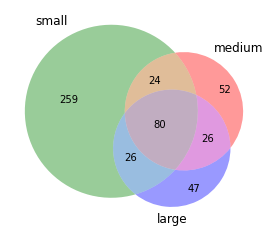

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib_venn import venn3

#chanteur = "Jacques Dutronc"

set1 = set(locatif_sm_before_pre_T)
set2 = set(locatif_md_before_pre_T)
set3 = set(locatif_lg_before_pre_T)

venn3([set1, set2, set3], ('small', 'medium', 'large'),set_colors=("green",
                             "red", "blue"))


plt.savefig("Data/Diagramme sur les EN avant pré-traitement de {}.png".format(chanteur))
plt.show()

In [14]:
lieux_intersection = []
lieux_intersection2 = []
lieux_intersection3 = []
#lieux_en_commun = []
for lieux in locatif_small_before_pre_T:
    if lieux in locatif_md_before_pre_T:
        if lieux in locatif_lg_before_pre_T:
            lieux_intersection.append(lieux)
for lieux2 in locatif_md_before_pre_T:
    if lieux2 in locatif_small_before_pre_T:
        if lieux2 in locatif_lg_before_pre_T:
            lieux_intersection2.append(lieux2)
for lieux3 in locatif_lg_before_pre_T:
    if lieux3 in locatif_small_before_pre_T:
        if lieux3 in locatif_md_before_pre_T:
            lieux_intersection3.append(lieux2)
#print(lieux_intersection3)
#print(lieux_intersection2)
#print(lieux_intersection)
lieux_en_com = set(lieux_intersection).intersection(lieux_intersection2)
lieux_en_com = list(lieux_en_com)
#lieux_en_commun = set(lieux_intersection3).intersection(lieux_en_com)
#print(len(lieux_en_com))
print(lieux_en_com)
print(locatif_lg_before_pre_T)

NameError: name 'locatif_small_before_pre_T' is not defined

In [ ]:
ll = []
ll2 = []
for lieux2 in locatif_md_before_pre_T:
    if lieux2 not in locatif_lg_before_pre_T:
        #if lieux2 not in locatif_small_before_pre_T:
            ll.append(lieux2)
for lieux in locatif_lg_before_pre_T:
    if lieux in locatif_md_before_pre_T:
        #if lieux not in locatif_md_before_pre_T:
            ll2.append(lieux)
            
print(ll)
print("-"*60)
print(ll2)

# Calcul des Proportions des EN de spacy

In [6]:
#récuperer les fichiers json
import os
import glob
import json
path = "proportion"

liste_fichiers = glob.glob("%s/*.json"%path)
#print(len(liste_fichiers))
#print(liste_fichiers)

In [14]:
#nlp = spacy.load('fr_core_news_sm') #modèle small
#nlp = spacy.load('fr_core_news_md') #modèle medium
nlp = spacy.load('fr_core_news_lg') #modèle large

modele = ["small", "medium", "large"]
modele_actif = 2

In [8]:
print(chanteur)
nbre_txt  = 0
for nom_artiste, liste_chansons in tqdm.tqdm(corpus.items()):
    if nom_artiste == chanteur:
        for element in liste_chansons:
            try:
                l = element["lyrics"]
                nbre_txt += 1
            except:
                nbre_txt += 1
print(nbre_txt)

100%|██████████████████████████████████████████████████████████████████████████| 1251/1251 [00:00<00:00, 617666.19it/s]

_113
96


In [9]:
#calcul de la proportion des EN de spacy
import nltk
from nltk.tokenize import word_tokenize
import re
import operator



compteur = 1
tokenizer = nltk.RegexpTokenizer(r"(\w+,\w+|\w+-\w+|\w+\.\w+\.\w+|\w+\S|\w+|\S|\w+\S|\?|\!)")
proportion_EN_locatif_spacy = {}
Proportion = []



if os.path.exists("proportion/proportion Entite nomme locatif spacy_{} {}.json".format(modele[modele_actif], chanteur)):
    with open("proportion/proportion Entite nomme locatif spacy_{} {}.json".format(modele[modele_actif], chanteur), encoding='UTF-8') as f:
        a = json.load(f)
        #print(a)
        for c, v in a.items():
            Proportion.append(v)
            #Proportion.append(i[1]) #reprend uniquement mon premier fichier json
else:
    for nom_artiste, liste_chansons in tqdm.tqdm(corpus.items()):
        if nom_artiste == chanteur:
            for element in liste_chansons:
                l = element["lyrics"]
                titre = element["full_title"]
                #print(l)
                try:    
                    doc = nlp(l)
                    entite_nomme = []
                    split_txt = Splittxt3(l) 
                    for ent in doc.ents:
                        if ent.label_ == "LOC":
                            locatif = ent.text
                        #print(ent.text, ent.label_)
                            entite_nomme.append(locatif)
                        proportion = len(entite_nomme)/len(split_txt)
                        proportion_EN_locatif_spacy[titre] = proportion
                    Proportion.append(proportion*100)
                    print("La proportion des EN sur la taille du texte {} est de".format(compteur), proportion*100, "%")
                    compteur += 1

                except:
                    #print(l)
                    Proportion.append(0)
                    proportion_EN_locatif_spacy[titre] = 0
                    print("La proportion des EN sur la taille du texte {} est de 0%".format(compteur))
                    compteur += 1

print(proportion_EN_locatif_spacy)
with open("proportion/proportion Entite nomme locatif spacy_{} {}.json".format(modele[modele_actif], chanteur), "w") as w:
    w.write(json.dumps(proportion_EN_locatif_spacy, indent=2))
"""print(len(Proportion))
count = 0
#print(liste_chansons)
#1/0
for nom_artiste, liste_chansons in tqdm.tqdm(corpus.items()):
    for element in liste_chansons:
        #print(element)
        titre = element["full_title"]
        essaie = [stat for stat in Proportion if stat not in proportion_EN_locatif_spacy]
        proportion_EN_locatif_spacy[titre] = essaie[count]
        #print(proportion_EN_locatif_spacy)
        count += 1
print(proportion_EN_locatif_spacy)
with open("proportion/proportion Entite nomme locatif spacy_{} {}.json".format(modele[modele_actif], chanteur), "w") as w:
    w.write(json.dumps(proportion_EN_locatif_spacy, indent=2))
print(proportion_EN_locatif_spacy)"""

{}


'print(len(Proportion))\ncount = 0\n#print(liste_chansons)\n#1/0\nfor nom_artiste, liste_chansons in tqdm.tqdm(corpus.items()):\n    for element in liste_chansons:\n        #print(element)\n        titre = element["full_title"]\n        essaie = [stat for stat in Proportion if stat not in proportion_EN_locatif_spacy]\n        proportion_EN_locatif_spacy[titre] = essaie[count]\n        #print(proportion_EN_locatif_spacy)\n        count += 1\nprint(proportion_EN_locatif_spacy)\nwith open("proportion/proportion Entite nomme locatif spacy_{} {}.json".format(modele[modele_actif], chanteur), "w") as w:\n    w.write(json.dumps(proportion_EN_locatif_spacy, indent=2))\nprint(proportion_EN_locatif_spacy)'

In [14]:
#calcul de la proportion des EN de spacy
import nltk
from nltk.tokenize import word_tokenize
import re
import operator

compteur = 1
tokenizer = nltk.RegexpTokenizer(r"(\w+,\w+|\w+-\w+|\w+\.\w+\.\w+|\w+\S|\w+|\S|\w+\S|\?|\!)")
proportion_EN_spacy = {}
Proportion4 = []


if os.path.exists("proportion/proportion Entite nomme spacy_{} {}.json".format(modele[modele_actif], chanteur)):
    with open("proportion/proportion Entite nomme spacy_{} {}.json".format(modele[modele_actif], chanteur), encoding='UTF-8') as f:
        a = json.load(f)
        #print(a)
        for c, v in a.items():
            Proportion4.append(v)
else:
    for nom_artiste, liste_chansons in tqdm.tqdm(corpus.items()):
        if nom_artiste == chanteur:
            for element in liste_chansons:
                l = element["lyrics"]
                titre = element["full_title"]
                try:

                    doc = nlp(l)
                    entite_nomme = []
                    split_txt = Splittxt3(l) 
                    for ent in doc.ents:

                        en = ent.text
                        #print(ent.text, ent.label_)
                        entite_nomme.append(en)
                    proportion = len(entite_nomme)/len(split_txt)
                    proportion_EN_spacy[titre] = proportion
                    Proportion4.append(proportion*100)
                    print("La proportion des EN sur la taille du texte {} est de".format(compteur), proportion*100, "%")
                    compteur += 1


                except:
                    #print(l)
                    proportion_EN_spacy[titre] = 0
                    Proportion4.append(0)
                    print("La proportion des EN sur la taille du texte {} est de 0%".format(compteur))
                    compteur += 1
with open("proportion/proportion Entite nomme spacy_{} {}.json".format(modele[modele_actif], chanteur), "w") as w:
    w.write(json.dumps(proportion_EN_spacy, indent=2))
    
"""count = 0
for element in liste_chansons:
    titre = element["full_title"]
    essaie = [stat for stat in Proportion4 if stat not in proportion_EN_spacy]
    #print(essaie)
    proportion_EN_spacy[titre] = essaie[count]
    count += 1
with open("proportion/proportion Entite nomme spacy_{} {}.json".format(modele[modele_actif], chanteur), "w") as w:
    w.write(json.dumps(proportion_EN_spacy, indent=2))
"""


  0%|                                                                                         | 0/1251 [00:00<?, ?it/s]

La proportion des EN sur la taille du texte 1 est de 8.250497017892645 %
La proportion des EN sur la taille du texte 2 est de 6.688963210702341 %
La proportion des EN sur la taille du texte 3 est de 0%
La proportion des EN sur la taille du texte 4 est de 0%
La proportion des EN sur la taille du texte 5 est de 7.113821138211382 %
La proportion des EN sur la taille du texte 6 est de 0%
La proportion des EN sur la taille du texte 7 est de 0%
La proportion des EN sur la taille du texte 8 est de 0%
La proportion des EN sur la taille du texte 9 est de 7.74869109947644 %
La proportion des EN sur la taille du texte 10 est de 6.6770186335403725 %
La proportion des EN sur la taille du texte 11 est de 9.333333333333334 %
La proportion des EN sur la taille du texte 12 est de 9.58904109589041 %
La proportion des EN sur la taille du texte 13 est de 8.422664624808576 %
La proportion des EN sur la taille du texte 14 est de 4.52755905511811 %
La proportion des EN sur la taille du texte 15 est de 8.3060

100%|██████████████████████████████████████████████████████████████████████████████| 1251/1251 [00:28<00:00, 44.12it/s]

La proportion des EN sur la taille du texte 96 est de 6.117021276595745 %


'count = 0\nfor element in liste_chansons:\n    titre = element["full_title"]\n    essaie = [stat for stat in Proportion4 if stat not in proportion_EN_spacy]\n    #print(essaie)\n    proportion_EN_spacy[titre] = essaie[count]\n    count += 1\nwith open("proportion/proportion Entite nomme spacy_{} {}.json".format(modele[modele_actif], chanteur), "w") as w:\n    w.write(json.dumps(proportion_EN_spacy, indent=2))\n'

In [15]:
print(json.dumps(proportion_EN_spacy, indent=2))

{
  "Tonton du bled by\u00a0113": 0.08250497017892644,
  "Un Jour de Paix by\u00a0113 (Ft.\u00a0Blacko\u00a0(FRA))": 0.06688963210702341,
  "Les Princes de la ville by\u00a0113": 0,
  "Partir Loin by\u00a0113 (Ft.\u00a0Reda\u00a0Taliani)": 0,
  "Demain J'arr\u00eate by\u00a0113": 0.07113821138211382,
  "Jackpotes 2000 by\u00a0113 (Ft.\u00a0Jmi\u00a0Sissoko)": 0,
  "Hold up by\u00a0113 (Ft.\u00a0Intouchable)": 0,
  "Marginal by\u00a0113": 0,
  "On sait l'faire by\u00a0113 (Ft.\u00a0Booba & Le\u00a0Rat Luciano)": 0.0774869109947644,
  "Au Summum by\u00a0113": 0.06677018633540373,
  "113 Fout La Merde by\u00a0113 (Ft.\u00a0Thomas\u00a0Bangalter)": 0.09333333333333334,
  "C\u00e9l\u00e9bration by\u00a0113 (Ft.\u00a0Awa\u00a0Imani & Jamel\u00a0Debbouze)": 0.0958904109589041,
  "Ouais Gros by\u00a0113": 0.08422664624808576,
  "Truc de fou by\u00a0113 (Ft.\u00a0Doudou\u00a0Masta)": 0.045275590551181105,
  "Trop puissant by\u00a0113": 0.08306010928961749,
  "Le Chant du Vice by\u00a0113 (Ft.\u

# Calcul des proportions des EN qui ont match avec les fichiers des lieux de paris

In [16]:
#Calcul de la proportion des EN qui ont matché avec la liste des lieux de paris
    #pour chaque txt si une entite nommé correspond a une vrai entite nommé alors
    #on ajoute le texte dans un dictionnaire et on ajoute l'entite nommé en valeur
import nltk
from nltk.tokenize import word_tokenize
import re
compteur = 0
tokenizer = nltk.RegexpTokenizer(r"(\w+,\w+|\w+-\w+|\w+\.\w+\.\w+|\w+\S|\w+|\S|\w+\S|\?|\!)")
proportion_EN_matché = {}
Proportion2 = []
en_Match = {}

liste_titre = []
if os.path.exists("proportion/proportion Entite matché_{} {}.json".format(modele[modele_actif], chanteur)):
    with open("proportion/proportion Entite matché_{} {}.json".format(modele[modele_actif], chanteur), encoding='UTF-8') as f:
        a = json.load(f)
        for i, c in a.items():
            Proportion2.append(c[1])
            en_Match[i]= [c[0], c[1], c[2]] #reprend uniquement mon premier fichier json
            
else:
    for nom_artiste, liste_chansons in tqdm.tqdm(corpus.items()):
        if nom_artiste == chanteur:
            for element in liste_chansons:

                txt = element["lyrics"]
                #print(element.keys())
                titre = element["full_title"]

                try:
                    artiste = element["album"]["artist"]["name"]
                except:
                    pass
                date = element["release_date"]
                en_Match.setdefault(titre,[])    
                if 2>1 :
                    try:
                        doc = nlp(txt)
                        liste_temporaire = []
                        freq = []
                        split_txt = Splittxt3(txt)
                        for ent in doc.ents:
                            liste_temporaire.append(ent.text)
                            #print(liste_temporaire)
                        match =  [i for i in liste_temporaire if i in vrai_entite_nomme]#Pour chaque match on calcul la proportion par texte.
                        proportion = (len(match)/len(split_txt))*100
                        print(proportion, "\n")
                        if match :
                            freq.append(match)   
                            en_Match[titre]= [match, proportion, len(freq)]
                        else:
                            en_Match[titre] = ["no match", 0, "none"]

                        Proportion2.append(proportion)

                    except:
                        Proportion2.append(0)
                        print("0\n")
                        en_Match[titre] = ["no match", 0, "none"]


with open("proportion/proportion Entite matché_{} {}.json".format(modele[modele_actif], chanteur), "w") as w:
    w.write(json.dumps(en_Match, indent=2))       
            
            
print(len(Proportion2))
#print(Proportion2)
#print(en_Match)
#print(proportion_EN_matché)

  0%|                                                                                         | 0/1251 [00:00<?, ?it/s]

0.09940357852882703 

0.0 

0

0

0.0 

0

0

0

0.10471204188481677 

0.0 

0.0 

0.12453300124533001 

0.0 

0.09842519685039369 

0.0 

0.0 

0

0

0

0

0

0.0 

0.0 

0

0.0 

0.26595744680851063 

0.0 

0.11961722488038277 

0

0

0

0.0 

0

0.0 

0

0

0.21645021645021645 

0

0.6200177147918512 

0

0.0 

0.0 

0

0

0.0 

0

0

0.22522522522522523 

0

0.0 

0

0.25252525252525254 

0.0 

0.0 

0

0.0 

0.0 

0.1314060446780552 

0

0.0 

0

0

0

0.0 

0.1953125 

0.0 

0

0.11806375442739078 

0.0 

0

0.0 

0.0 

0

0

0.0 

0

0.11737089201877934 

0.0 

0.24630541871921183 

0

0

0.0 

0.0 

0

0.0 

0

0.0 

0

0.0 

0

0

0

0

0

0.0 



100%|██████████████████████████████████████████████████████████████████████████████| 1251/1251 [00:18<00:00, 66.86it/s]

0.0 

96


In [26]:
print(json.dumps(en_Match, indent=2))

{
  "Mini, Mini, Mini by\u00a0Jacques\u00a0Dutronc": [
    "no match",
    0,
    "none"
  ],
  "Et Moi, Et Moi, Et Moi by\u00a0Jacques\u00a0Dutronc": [
    "no match",
    0,
    "none"
  ],
  "Les Cactus by\u00a0Jacques\u00a0Dutronc": [
    "no match",
    0,
    "none"
  ],
  "Fais Pas Ci, Fais Pas \u00c7a by\u00a0Jacques\u00a0Dutronc": [
    "no match",
    0,
    "none"
  ],
  "Il Est Cinq Heures, Paris S'Eveille by\u00a0Jacques\u00a0Dutronc": [
    "no match",
    0,
    "none"
  ],
  "J'aime les filles by\u00a0Jacques\u00a0Dutronc": [
    "no match",
    0,
    "none"
  ],
  "Les Playboys by\u00a0Jacques\u00a0Dutronc": [
    "no match",
    0,
    "none"
  ],
  "Hippie Hippie Hourrah by\u00a0Jacques\u00a0Dutronc": [
    "no match",
    0,
    "none"
  ],
  "L'Opportuniste by\u00a0Jacques\u00a0Dutronc": [
    "no match",
    0,
    "none"
  ],
  "La Fille Du P\u00e8re No\u00ebl by\u00a0Jacques\u00a0Dutronc": [
    "no match",
    0,
    "none"
  ],
  "Le Responsable by\u00a0Jacqu

# Proportion des lettres capitale dans les textes

In [17]:

import nltk
from nltk.tokenize import word_tokenize
import re

compteur = 0
proportion_maj = {}
Proportion3 = []
tokenizer = nltk.RegexpTokenizer(r"(\w+,\w+|\w+-\w+|\w+\.\w+\.\w+|\w+\S|\w+|\S|\w+\S|\?|\!)")

if os.path.exists("proportion des majuscules {}.json".format(chanteur)):
    with open(path_json) as f:
        cle, valeur = json.load(f)
        Proportion3.append(valeur)
else:
     for nom_artiste, liste_chansons in tqdm.tqdm(corpus.items()):
        if nom_artiste == chanteur:
            for element in liste_chansons:
                i = element["lyrics"]
                if 2 > 1:
                    if i != None:                    
                        majuscule = []
                        txt_split = Splittxt3(i)
                        #print(txt_split)
                        for eleme in txt_split:
                            if eleme.istitle() == True:
                                majuscule.append(eleme)
                                proportion = (len(majuscule)/len(txt_split))*100
                                proportion_maj[titre] = proportion
                        Proportion3.append(proportion)
                        compteur += 1
                        print("La proportion des mots en majuscule sur le texte n°{} est de {}".format(compteur, proportion),"%")
                        print("Il y a %s Mot qui on une maj sur %s mot \n"%(len(majuscule), len(txt_split)))

                        #print(majuscule)


                    else:
                        #print(i)
                        proportion_maj[titre] = proportion
                        Proportion3.append(0)
                        compteur += 1
                        print("La proportion des mots en majuscule sur le texte n°{} est de 0% \n".format(compteur))

with open("proportion/proportion des majuscules {}.json".format(chanteur), "w") as w:
    w.write(json.dumps(proportion_maj, indent=2))


"""count = 0
for element in liste_chansons:
    titre = element["full_title"]
    essaie = [stat for stat in Proportion3 if stat not in proportion_maj]
    #print(essaie)
    proportion_maj[titre] = essaie[count]
    count += 1"""



100%|███████████████████████████████████████████████████████████████████████████| 1251/1251 [00:00<00:00, 20018.37it/s]

La proportion des mots en majuscule sur le texte n°1 est de 13.817097415506957 %
Il y a 139 Mot qui on une maj sur 1006 mot 

La proportion des mots en majuscule sur le texte n°2 est de 11.594202898550725 %
Il y a 104 Mot qui on une maj sur 897 mot 

La proportion des mots en majuscule sur le texte n°3 est de 0% 

La proportion des mots en majuscule sur le texte n°4 est de 0% 

La proportion des mots en majuscule sur le texte n°5 est de 12.804878048780488 %
Il y a 126 Mot qui on une maj sur 984 mot 

La proportion des mots en majuscule sur le texte n°6 est de 0% 

La proportion des mots en majuscule sur le texte n°7 est de 0% 

La proportion des mots en majuscule sur le texte n°8 est de 0% 

La proportion des mots en majuscule sur le texte n°9 est de 13.298429319371726 %
Il y a 127 Mot qui on une maj sur 955 mot 

La proportion des mots en majuscule sur le texte n°10 est de 12.577639751552795 %
Il y a 81 Mot qui on une maj sur 644 mot 

La proportion des mots en majuscule sur le texte 

'count = 0\nfor element in liste_chansons:\n    titre = element["full_title"]\n    essaie = [stat for stat in Proportion3 if stat not in proportion_maj]\n    #print(essaie)\n    proportion_maj[titre] = essaie[count]\n    count += 1'

In [28]:
print(json.dumps(proportion_maj, indent=2))

{
  "Mini, Mini, Mini by\u00a0Jacques\u00a0Dutronc": 23.61111111111111,
  "Et Moi, Et Moi, Et Moi by\u00a0Jacques\u00a0Dutronc": 14.766839378238341,
  "Les Cactus by\u00a0Jacques\u00a0Dutronc": 26.06837606837607,
  "Fais Pas Ci, Fais Pas \u00c7a by\u00a0Jacques\u00a0Dutronc": 16.666666666666664,
  "Il Est Cinq Heures, Paris S'Eveille by\u00a0Jacques\u00a0Dutronc": 0,
  "J'aime les filles by\u00a0Jacques\u00a0Dutronc": 19.36936936936937,
  "Les Playboys by\u00a0Jacques\u00a0Dutronc": 0,
  "Hippie Hippie Hourrah by\u00a0Jacques\u00a0Dutronc": 21.978021978021978,
  "L'Opportuniste by\u00a0Jacques\u00a0Dutronc": 0,
  "La Fille Du P\u00e8re No\u00ebl by\u00a0Jacques\u00a0Dutronc": 26.217228464419474,
  "Le Responsable by\u00a0Jacques\u00a0Dutronc": 12.781954887218044,
  "L'idole by\u00a0Jacques\u00a0Dutronc": 9.666666666666666,
  "On Nous Cache Tout, On Nous Dit Rien by\u00a0Jacques\u00a0Dutronc": 16.030534351145036,
  "L'Idole (Je N'En Peux Plus) by\u00a0Jacques\u00a0Dutronc": 17.716535433

# initialisation d'un dic pr overleaf

In [28]:

dictionnaire_tableau = {}
compteuur = 0

valeur1 = [v for v in Proportion]
valeur2 = [v for v in Proportion4]
valeur3 = [v for v in Proportion2]
valeur4 = [v for v in Proportion3]
print(valeur1[compteuur])
for nom_artiste, liste_chansons in tqdm.tqdm(corpus.items()):
    if nom_artiste == chanteur:
        for element in liste_chansons:
            titre = element["full_title"]
            dictionnaire_tableau[titre] = [valeur1[compteuur], valeur2[compteuur], valeur3[compteuur], valeur4[compteuur]]
            compteuur += 1

print(dictionnaire_tableau)


  0%|                                                                                         | 0/1251 [00:00<?, ?it/s]

0.027833001988071572


IndexError: list index out of range

# affichage pr overleaf


In [30]:

nom_colone = ["Titre chanson", "Prop locatif","Prop EN", "Prop match", "Prop Maj"]
print("\\begin{table}")
print("\\centering")
print("\t\\begin{tabular}{|l|l|l|l|l|}")
print("\t\\hline")
print(" \t %s \\\\" %(" & ".join(nom_colone)))
print("\t\\hline")
#ne pas trier les valeurs tant que toutes les valeurs ne sont pas inscrite.
#ou une boucle qui récupère pour chaque titre leurs valeurs.
for titre, proportion in sorted(dictionnaire_tableau.items(), key=lambda x: x[1], reverse=True):
    ligne = "\t %s... \t& %s \t& %s \t& %s \t& %s \\\\\n\t\\hline  " %(str(titre[:20]), round(proportion[0], 4), round(proportion[1], 4), round(proportion[2], 4), round(proportion[3], 4))
    print(ligne)
print("\t\end{tabular}")
print("\end{table}")

\begin{table}
\centering
	\begin{tabular}{|l|l|l|l|l|}
	\hline
 	 Titre chanson & Prop locatif & Prop EN & Prop match & Prop Maj \\
	\hline
	 L'Aventurier by Jacq... 	& 7.5099 	& 20.5761 	& 0.3953 	& 26.087 \\
	\hline  
	 Merde In France (Cac... 	& 3.3079 	& 16.2602 	& 0 	& 19.084 \\
	\hline  
	 Le Petit Jardin by J... 	& 2.3438 	& 5.3942 	& 0 	& 18.75 \\
	\hline  
	 Mini, Mini, Mini by ... 	& 2.0833 	& 22.5225 	& 0 	& 23.6111 \\
	\hline  
	 Mini, mini, mini - r... 	& 2.0833 	& 22.5225 	& 0 	& 23.6111 \\
	\hline  
	 Brèves Rencontres by... 	& 1.9481 	& 14.7287 	& 0 	& 29.8701 \\
	\hline  
	 Le Courrier Du Cœur ... 	& 1.8692 	& 8.867 	& 0 	& 19.6262 \\
	\hline  
	 Le Testamour by Jacq... 	& 1.8182 	& 20.1258 	& 0 	& 37.5758 \\
	\hline  
	 Le Roi De La Fête by... 	& 1.6484 	& 9.4801 	& 0.2747 	& 26.9231 \\
	\hline  
	 Les Roses Fanées by ... 	& 1.4815 	& 13.0435 	& 0 	& 20.7407 \\
	\hline  
	 Transat En Solitaire... 	& 1.3889 	& 11.165 	& 0 	& 31.9444 \\
	\hline  
	 J'aime les filles by.

# code pour regrouper les lieux de paris.

In [31]:

liste_inclassable = []
for lieux in vrai_entite_nomme:
    liste_inclassable.append(lieux)
    dic_lieu["unclassable"] = set(liste_inclassable)
    #print(dic_lieu)
dic_lieu = {"inclassable":set(vrai_entite_nomme)}
def regroupement_lieu_paris(expression_reguliere, cle, dic_lieu):
    liste_classable = []
    for lieux in vrai_entite_nomme:
        match = re.search(expression_reguliere, lieux)#re.I ?
        if not match:
            pass    
        else:
            liste_classable.append(lieux)
    dic_lieu[cle] = set(liste_classable)
    return dic_lieu
for expr, cle in [
    [r'^(Chateau|chateau|château|Château)', "Chateau"],
    [r'^(Porte|porte)', "Porte"],
    [r'^(Eglise|eglise|Église|église)',"Eglise"],
    [r'^(Place|place)', "Place"],
    [r'^(Avenue|avenue)',"Avenue"],
    #[r'Michel', "Michel"],
    [r'^(Boulevard|boulevard)', "Boulevard"],
    [r'^(Rue|rue)', "Rue"],
    [r'^(Cite|cite|Cité|cité)', "Cite"],
    [r'Paris ([0][1-9]|[1][0]|[1][1-9]|20|arrondissement)$', "Arrondissement"],
    [r'^(Saint|saint|st|St)',  "Saint"],
    [r'^(Pont|pont|ponts|Ponts)', "Pont"]]:
    dic_lieu = regroupement_lieu_paris(expr, cle, dic_lieu)
    dic_lieu["inclassable"] = dic_lieu["inclassable"].difference(dic_lieu[cle])
   


#print("")
taille_voc = len(set(vrai_entite_nomme))
print(taille_voc)
#print(dic_lieu)
dic_lieu_to_overleaf = {}
for cle, liste in dic_lieu.items():
    dic_lieu_to_overleaf[cle] = len(dic_lieu[cle])
    #print(cle, len(dic_lieu[cle]))
#print("-"*60)
#print(dic_lieu_to_overleaf)
for cle, liste in sorted(dic_lieu_to_overleaf.items(), key=lambda x: x[1], reverse=True):
    #print(len(dic_lieu[cle]))
    print(cle,"|", len(dic_lieu[cle]), "|",  len(dic_lieu[cle])/taille_voc)
#print(dic_lieu["Arrondissement"])




8507
inclassable | 3517 | 0.41342423886211355
Rue | 3464 | 0.4071940754672623
Place | 515 | 0.060538380157517335
Avenue | 350 | 0.04114258845656518
Eglise | 132 | 0.015516633360761726
Saint | 120 | 0.014106030327965206
Boulevard | 117 | 0.013753379569766074
Cite | 114 | 0.013400728811566944
Porte | 99 | 0.011637475020571294
Pont | 37 | 0.004349359351122605
Chateau | 22 | 0.0025861055601269544
Arrondissement | 20 | 0.0023510050546608676


# Code pour construction tableau overleaf

In [32]:

nom_tableau = ["Lieu", "taille", "proportion"]
print("\t\\begin{tabular}{|l|l|l|}")
print("\t\\hline")
print(" \t %s \\\\" %(" & ".join(nom_tableau)))
print("\t\\hline")

for cle, valeur in sorted(dic_lieu_to_overleaf.items(), key=lambda x: x[1], reverse=True):
    ligne = "\t %s \t& %s \t& %s \\\\\n\t\\hline  "%(cle, len(dic_lieu[cle]),len(dic_lieu[cle])/taille_voc)
    print(ligne)
print("\t\end{tabular}")
print("\end{table}") 

	\begin{tabular}{|l|l|l|}
	\hline
 	 Lieu & taille & proportion \\
	\hline
	 inclassable 	& 3517 	& 0.41342423886211355 \\
	\hline  
	 Rue 	& 3464 	& 0.4071940754672623 \\
	\hline  
	 Place 	& 515 	& 0.060538380157517335 \\
	\hline  
	 Avenue 	& 350 	& 0.04114258845656518 \\
	\hline  
	 Eglise 	& 132 	& 0.015516633360761726 \\
	\hline  
	 Saint 	& 120 	& 0.014106030327965206 \\
	\hline  
	 Boulevard 	& 117 	& 0.013753379569766074 \\
	\hline  
	 Cite 	& 114 	& 0.013400728811566944 \\
	\hline  
	 Porte 	& 99 	& 0.011637475020571294 \\
	\hline  
	 Pont 	& 37 	& 0.004349359351122605 \\
	\hline  
	 Chateau 	& 22 	& 0.0025861055601269544 \\
	\hline  
	 Arrondissement 	& 20 	& 0.0023510050546608676 \\
	\hline  
	\end{tabular}
\end{table}


# pré-traitement adaptation casse
Si le mot au début de la ligne est en majuscule, on le met en minuscule s'il valide les deux conditions suivantes :

- Il "existe en minuscule dans le Glaff"

- Il "n'es pas pas dans la ressource de noms de lieux"

Par exemple, si j'ai :

Il est maxi Docteur Schweitzer Il- --> il

Maximum et maxibus Maximum --> maximum

Maxistère et termaxus --> maxistère

par contre dans

"Paris et province" --> Paris ne bouge pas car s'il existe en minuscule dans le Glaff il est présent dans la ressource

La véritable "recréation" de phrases ce sera une étape pour plus tard, car ça va être assez compliqué !

In [33]:
"""import re

path = "GLAFF/glaff-1.2.2.txt"
f = open(path, encoding='UTF-8')

ligne = f.readline()
cpt=0
dic_glaff = {}
while len(ligne)>1:
    cpt+=1
    elems = re.split("\|", re.sub("\n", "", ligne))
    freq = 0
    forme = elems[0]
    for index in range(6, len(elems)+1, 2):
        freq+=float(elems[index])
    dic_glaff[forme] = freq
    ligne = f.readline()
    cpt = 10000"""
#w = open("freq_glaff_%i.json"%cpt, "w")
#w.write(json.dumps(dic_glaff, indent=2))
#w.close()


'import re\n\npath = "GLAFF/glaff-1.2.2.txt"\nf = open(path, encoding=\'UTF-8\')\n\nligne = f.readline()\ncpt=0\ndic_glaff = {}\nwhile len(ligne)>1:\n    cpt+=1\n    elems = re.split("\\|", re.sub("\n", "", ligne))\n    freq = 0\n    forme = elems[0]\n    for index in range(6, len(elems)+1, 2):\n        freq+=float(elems[index])\n    dic_glaff[forme] = freq\n    ligne = f.readline()\n    cpt = 10000'

In [157]:
import json
#voc_glaff = []
with open("freq_glaff_10000.json") as f:
    dic = json.load(f)
    print(len(dic))
    voc_glaff = set(dic.keys()) 
    print(len(voc_glaff))

mot = "météoriser"
if mot in voc_glaff:
    print(mot)

1082688
1082688
météoriser


In [155]:
import json
import tqdm
corpus = ouvrir_json("tmp.json")
chanteur = []
cpt = 0

#with open("all_entites.json", encoding="utf-8") as f:
    #all_entites = json.load(f)
for nom_artiste, liste_chansons in tqdm.tqdm(corpus.items()):
    chanteur.append(nom_artiste)
    for element in liste_chansons:
        #txt = element["lyrics"]
        try:
            txt = element["lyrics"]
            #txt = str(txt)
        except:
            continue
        titre = element["full_title"]




 11%|████████▋                                                                    | 142/1251 [00:00<00:00, 1388.24it/s]

0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme artiste vue
0 eme arti

 42%|████████████████████████████████▌                                            | 529/1251 [00:00<00:00, 1571.17it/s]

 _EddieLundell
_EddydePretto _EddydePretto
_EddyMitchell _EddyMarnay
_EddyMitchell _EddyMitchell
_EdithLefel _EdithLefel
_ÉdithPiaf _ÉdithPiaf
_Eileen _EdmondTanière
_Eileen _Eileen
_Elias _Elias
_ElieSémoun _ElieSémoun
_ElisabethAnais _ElisabethAnais
_Elisabethkontomanou _Elisabethkontomanou
_ElisaTovati _ElisaTovati
_ElmerFoodBeat _ElmerFoodBeat
_ÉlodieFrégé _ÉlodieFrégé
_ElsaEsnoult _ElsaEsnoult
_ElsaLunghini _ElsaLunghini
_ÉmilieSimon _EmileAudifred
_ÉmilieSimon _EmileJeanMercadier
_ÉmilieSimon _ÉmilieSimon
_EmilyLoizeau _EmilyLoizeau
_EmmaDaumas _EmmaDaumas
_EmmanuelleSeigner _EmmanuelBooze
_EmmanuelleSeigner _EmmanuelDahl
_EmmanuelleSeigner _EmmanuelleMonet
_EmmanuelleSeigner _EmmanuelleSeigner
_EmmanuelMoire _EmmanuelMoire
_EmmaShapplin _EmmaShapplin
_EmyLTR _EmyLTR
_EnricoMacias _EnricoMacias
_EnzoEnzo _EnzoEnzo
_EreLeMissile _EnzoRatsito
_ÉricEstève _EreLeMissile
_ÉricEstève _ÉricEstève
_EricLévi _EricLaveine
_ÉricToulis _EricLévi
_ÉricToulis _ÉricToulis
_ErikArnaud _ErikArnau

 71%|██████████████████████████████████████████████████████▉                      | 893/1251 [00:00<00:00, 1717.54it/s]

_Karimouche _Karimouche
_Katerine _KarineCosta
_Katerine _KarineLima
_Katerine _Katerine
_Kayliah _Kayliah
_KaynaSamet _KaynaSamet
_Kazero _Kazero
_KeBlack _KeBlack
_Keedz _Keedz
_KeenV _KeenV
_KellyJoyce _KellyJoyce
_KendjiGirac _KendjiGirac
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste vue
700 eme artiste v

100%|████████████████████████████████████████████████████████████████████████████| 1251/1251 [00:00<00:00, 1673.08it/s]


_RekmanSeller _RafaelPérezMedina
_RekmanSeller _RaouldeGodewarsvelde
_RekmanSeller _RéjanePerry
_RekmanSeller _RekmanSeller
_RenaudHantson _RenaudHantson
_Renaud _Renaud
_RenéJoly _RenaudPapillonParavel
_Renelataupe _RenéJoly
_RicetBarrier _Renelataupe
_RicetBarrier _RicetBarrier
_RichardAnthony _RichardAnthony
_RichardBohringer _RichardBohringer
_RichardGotainer _RichardCharest
_RichardGotainer _RichardGotainer
_RickyShayne _RickyShayne
_Ricoune _Ricoune
_Ridan _Ridan
_Ridsa _Ridsa
_RinaKetty _RinaKetty
_RitaCadillac _RitaCadillac
_RodJanois _RobertGall
_RodJanois _RobertNyel
_RodJanois _RodJanois
_RodolpheBurger _RodolpheBurger
_RogerMason _RogerBourdin
_RogerMason _RogerMason
_RomainDidier _RomainDidier
_RomainHumeau _RomainHumeau
_RomaneSerda _RomaneSerda
_RoseLaurens _RomualdFiguier
_RosemaryStandley _RosalieDubois
_RosemaryStandley _RoseLaurens
_RosyArmen _RosemaryStandley
_Rouda _RosyArmen
_Rouda _Rouda
_R.Wan _R.Wan
_SabinePaturel _SabinePaturel
_SachaDistel _SachaDistel
_Sand

In [ ]:

  
  #print(nom_artiste)
  
    
   
    titre = element["full_title"]
    all_entites.setdefault(nom_artiste, {})
    all_entites[nom_artiste].setdefault(titre, {})
    if cpt%100==0:
        print(cpt, "chansons faites")
    if len(all_entites[nom_artiste][titre])==3:
        cpt+=1
        continue
    for nom_modele, nlp in liste_models:
        if nom_modele not in  all_entites[nom_artiste][titre]:
            doc = nlp(txt)
            entites = [ent.text for ent in doc.ents if ent.label_=="LOC"]
            all_entites[nom_artiste][titre][nom_modele]= entites
    cpt+=1
    #liste_txt.append(txt)
    #tous_les_txt.append(liste_txt)
    if cpt%100==0:
        break
  if cpt%100==0:
        break
    
    #print(titre)
    #print(liste_txt, "-"*70)print(len(tous_les_txt))
print(cpt, "chansons faites")
#chanteur = "Jacques Dutronc"
#with open("all_entites.json", "w", encoding="utf-8") as w:
    #w.write(json.dumps(all_entites, indent=2, ensure_ascii=False))
#print(json.dumps(all_entites, indent =2))

In [158]:
import nltk
chanson = []
for nom_artiste, donnee in tqdm.tqdm(corpus.items()):
    #if nom_artiste == chanteur:
    if 2>1:
        for element in donnee:
            liste = []
            txt = element["lyrics"]
            try:
                for l in txt.split("\n"):
                    #lignes_chanson.append(l)
                    liste.append(l)
                chanson.append(liste) #lignes_chanson.append([l])
            except:
                chanson.append([])
        
FP = 0 # On a modifié et on a eu tord
VP = 0 # On a modifié et on a eu raison
FN = 0 # On a pas modifié et on a eu tord
VN = 0 # On a pas modifié et on a eu raison.

#print(chanson)
count = -1
for liste_lignes_chanson in tqdm.tqdm(chanson):
    count += 1
    for ligne in liste_lignes_chanson:
        expr = re.compile("^(\w+'|\w+-\w+|\w+)")
        match = expr.finditer(ligne)
        
        #print(ligne)
        #ici je créer une expression pour récuperer tous les mots en début de ligne, 
        #certain commençant par "j'" ou "c'" d'autre par un tiret "un-mot", je ne sais pas s'il y a
        #d'autre mot différent.
    #------------------------------------------------------------------------------------------------------------ 
        for m in match:
            mot = m.group(0) #la variable mot prend la chaine de caractère trouvé par mon match.
            #print(""" "{}"  dans : "{}" """.format(mot, z)) #affiche le mot dans quel ligne il se trouve.
            toto = False
            if mot[0] != mot[0].lower():
                toto = True
            #if mot.istitle(): #si le mot possède une majuscule je le met sans maj. minimoke not istitle()
            if toto == True:
                mot_lower = mot.lower()
                #print(mot)
    #------------------------------------------------------------------------------------------------------------
                if mot_lower in voc_glaff:                 #s'il est dans le glaff et qu'il correspond 
                    #print("le mot est dans glaff")   #a un lieu de ma liste des lieux
                    if mot in vrai_entite_nomme:     #SINON je l'affiche .
                        print("le mot est un nugget\n ")
                        FP += 1
                    else:
                        
                        #print("je suis pas un nugget\n ")
                        liste_mots = Splittxt3(ligne)#permet de découper ma ligne en liste de mot.
                        #print(liste_mots)
                        #1/0
                        #print(liste_mots)
                        liste_mots[0] = mot_lower            #le mot en début de ligne je le remplace par mot.
                        nouvelle_ligne = " ".join(liste_mots)  #je reassemble ma ligne.
                        for apo in ["’", "'"]:
                          nouvelle_ligne = re.sub(f"{apo} ", f"{apo}", nouvelle_ligne)
                          nouvelle_ligne = re.sub(f" {apo}", f"{apo}", nouvelle_ligne)
                        #nouvelle_ligne = re.sub("\'\s", "\'", nouvelle_ligne)
                        #print(lignes_chanson, "\n")
                        res = [elem.replace(ligne,nouvelle_ligne) for elem in liste_lignes_chanson]  #je remplace 
                        VP += 1
                        liste_lignes_chanson = res   #l'ancienne ligne par une nouvelle ligne.  #VP 
                        chanson[count] = liste_lignes_chanson
                    

                        
    #------------------------------------------------------------------------------------------------------------

                elif mot_lower not in voc_glaff:#s'il est pas dans le glaff je fait le même procédé ↑.

                    #print("le mot est pas dans glaff \n ")#ne pas mettre en minuscule. #FN
                    #match = [i for i in vrai_entite_nomme]
                    if mot not in vrai_entite_nomme:
                        #print("pas dans lieu de paris")
                        FN += 1
                    else:
                        #print("je suis un lieu de paris \n ")
                        VN += 1

#print(chanson)
#print(count)
#print(len(chanson))
#Problème au niveau du .join les mots comme l'index sont écrit de cet manière l' index.

  0%|                                                                               | 48/34819 [00:00<06:35, 87.92it/s]

le mot est un nugget
 


  0%|▏                                                                             | 96/34819 [00:00<04:15, 135.84it/s]

le mot est un nugget
 


  0%|▎                                                                            | 148/34819 [00:01<05:42, 101.35it/s]

...

le mot est un nugget
 
le mot est un nugget
 


 99%|██████████████████████████████████████████████████████████████████████████▍| 34547/34819 [03:42<00:01, 211.74it/s]

le mot est un nugget
 
le mot est un nugget
 


100%|███████████████████████████████████████████████████████████████████████████| 34819/34819 [03:43<00:00, 155.73it/s]

le mot est un nugget
 
le mot est un nugget
 
le mot est un nugget
 
le mot est un nugget
 


In [31]:
print(chanson)

[['[Introduction]', 'Hé tonton, les cabas ils sont trop lourds !', 'Aaaahhhh, allez montez dans la voiture !', 'monte Bilal et Atmen', 'allez monte , monte', 'allez on y va , on y va', 'Hey 3ami Karim', 'tonton du bled', 'pour tous les " misstmout "', 'Wled el bledi', '', '[Refrain]', 'J\'voulais rester à la cité mon père m\'a dit "Lé, lé, la"', 'dans c\'cas - là j\'ramène tous mes amis , " Lé , lé , la "', 'alors dans une semaine j\'rentre à Vitry , " Lé , lé , la "', 'J\'irai finir mes jours là-bas "Wah, wah, wah"', '', '[Couplet 1]', '504 Break chargé, allez montez les neveux', 'juste un instant que je mette sur le toit la grosse malle bleue', 'nombreux comme une équipe de foot , voiture à ras du sol', 'on est les derniers locataires qui décollent', "le plein de gasoil et d'gazouz pour pas flancher", "Bilel va pisser le temps qu'j'fasse mon p'tit marché", "direction l'port , deux jours le pied sur l'plancher", "jusqu''à Marseille avec la voiture un peu penchée", "plus 24h de bateau 

In [184]:
comptage = 0

num_chanson = []

for i in tqdm.tqdm(chanson):
    m = []
    nv_echantillon = " \n ".join(i)
    m.append(nv_echantillon)
    #print(m)
    #num_chanson.append(nv_echantillon)
    num_chanson.append(m)
    #print(num_chanson[comptage])
        
    #print(num_chanson[comptage], "\n")
        
        
#print(num_chanson[0])    
Dic_nouvelle_chansons = {}
#Dic_nouvelle_chansons.setdefault(nom_artiste,[])
#Dic_nouvelle_chansons[nom_artiste] = []
#print(Dic_nouvelle_chansons)
#Dic_nouvelle_chansons["all"].setdefault(,[])


for nom_artiste, donnee in tqdm.tqdm(corpus.items()):
    Dic_nouvelle_chansons.setdefault(nom_artiste,[])
    #if nom_artiste == chanteur:
    if 2>1:
        for element in donnee:
            #Dic_nouvelle_chansons.setdefault()
            titre = element["full_title"]
            try:
                artiste = element["album"]["artist"]["name"]
            except:
                artiste = "none"
            try:
                date = element["release_date"]
            except:
                date = "None"
            #if titre not in Dic_nouvelle_chansons:
            if 2>1:
                dic_tempo = {"Titre_chanson":titre, "Auteur":artiste, "lyrics":num_chanson[comptage], "Date":date}
                Dic_nouvelle_chansons[nom_artiste].append(dic_tempo)
                #print(Dic_nouvelle_chansons)
                ###Dic_nouvelle_chansons["all"]["Auteur"] = artiste
                #Dic_nouvelle_chansons["all"]["lyrics"] = num_chanson[comptage]
                comptage += 1
        #print(Dic_nouvelle_chansons)
    #print(nom_artiste)
    #print(Dic_nouvelle_chansons)
with open("Data/parole pre traiter/nouvel_echantillon.json", "w") as w:
    w.write(json.dumps(Dic_nouvelle_chansons, indent=2))


#for toto in Dic_nouvelle_chansons["all"][:5]:
    #print(json.dumps(toto, indent=2))#

100%|█████████████████████████████████████████████████████████████████████████████| 1251/1251 [00:09<00:00, 131.34it/s]


ZeroDivisionError: division by zero

In [181]:
#print(Dic_nouvelle_chansons)

# Matrice de confusion

In [186]:
print("FP = ",FP)
print("VP = ",VP)
print("FN = ",FN)
print("VN = ",VN)
confusion_matrice = FP, VP, FN, VN

FP =  1127
VP =  552420
FN =  171862
VN =  129


In [4]:
FP =  0
VP =  1262
FN =  307
VN =  2

In [5]:
accuracy = VP/(VP + FP)
rappel = VP / (VP + FN)
f_mesure = (2*(accuracy*rappel))/(accuracy+rappel)
print("accuracy = ",accuracy)
print("rappel = ",rappel)
print("f_mesure = ",f_mesure)

accuracy =  1.0
rappel =  0.804333970681963
f_mesure =  0.8915577534440127


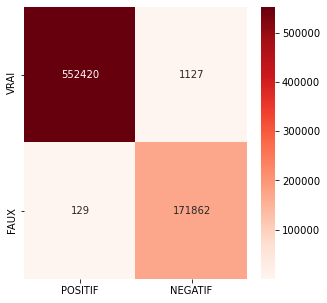

In [189]:
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt
array = [[VP,FP],
        [VN, FN]]
fig, ax = plt.subplots(figsize=(5,5))
df_cm = pd.DataFrame(array, index=["VRAI", "FAUX"], columns=["POSITIF","NEGATIF"])
# plt.figure(figsize=(10,7))

#sn.set(font_scale=1) # for label size
sn.heatmap(df_cm, annot=True, cmap = plt.cm.Reds, fmt ="d") # font size
plt.savefig("Data/Matrice_confusion_{}.png".format("all_artiste"))
plt.show()

# Récuperer mon nouveau fichier json et detecter les EN dessus.
for i in chanson:
    #print(i)
    nv_echantillon = "\n".join(i)
    #print(nv_echantillon)
    doc = nlp(nv_echantillon)
    for ent in doc.ents:
        if ent.label_ == "LOC":
            locatif = ent.text
            print(locatif)
            if locatif in vrai_entite_nomme:
                print("#"*79, "\n", locatif,"\n","#"*79)

In [78]:
#chanteur = "_113"

In [11]:
path_to_Spacy = "Data/parole pre traiter/nouvel_echantillon.json"

corpus2 = ouvrir_json(path_to_Spacy)
#print(i)


In [ ]:
#statt sur le corpus

In [12]:
import tqdm
import json
nom_artiste = " "
corpus2 = ouvrir_json(path_to_Spacy)
artiste = []
toutes_les_chansons = []
tous_les_mots = []
nbre_de_texte_traitable = 0
nbre_de_texte_non_traitable = 0
nbre_de_mot_totale = 0
nbre_de_mot_par_chanson = []
dic_nbre_de_mot = {}
dic_nbre_de_mot = {nom_artiste:{}, titre:{}}

for nom_artiste, donnee in tqdm.tqdm(corpus.items()):
    for element in donnee:
        chansons = []
        titre = element["full_title"]
        try:
            #txt = str(parole)
            parole = element["lyrics"]
            mots = Splittxt3(parole)
            chansons.append(mots)
            dic_nbre_de_mot[titre].setdefault(len(mots), 0)
            dic_nbre_de_mot[titre][len(mots)]+=1 
            dic_nbre_de_mot[nom_artiste].setdefault(len(chansons), 0)
            dic_nbre_de_mot[nom_artiste][len(chansons)]+=1
            #chansons.append(parole)
            #toutes_les_chansons.append(chansons)
            #nbre_de_texte_traitable += 1
            #print(dic_nbre_de_mot)
            #1/0
        except:
            pass
            #mots = None
            #chansons.append(mots)
            #dic_nbre_de_mot[titre].setdefault(mots, 0)
            #dic_nbre_de_mot[titre][0]+=1 
            #dic_nbre_de_mot[nom_artiste].setdefault(len(chansons), 0)
            #dic_nbre_de_mot[nom_artiste][len(chansons)]+=1
            #chansons.append(None)
            #toutes_les_chansons.append(chansons)
            #nbre_de_texte_non_traitable += 1
            #print(dic_nbre_de_mot)
            #1/0
        
        #print(dic_nbre_de_mot)
        #1/0
        

print(dic_nbre_de_mot)   
        
        
        
        
        
        
        
"""
for liste_chansons in tqdm.tqdm(toutes_les_chansons):
    for chanson in liste_chansons:
        try:
            mots = Splittxt3(chanson)
            tous_les_mots.append(mots)
        except:
            tous_les_mots.append([])
        if chanson != None:
            nbre_de_texte_traitable += 1
        else:
            nbre_de_texte_non_traitable += 1
    #artiste.append(chanteur)
print(nbre_de_texte_non_traitable)
print(nbre_de_texte_traitable)
#print(tous_les_mots)
for liste_mots in tqdm.tqdm(tous_les_mots):
    nbre_de_mot_par_chanson.append(len(liste_mots))
    nbre_de_mot_par_chanson.append(0)
    for mot in liste_mots:
        nbre_de_mot_totale += 1
#print(nbre_de_mot_par_chanson)
#print(nbre_de_mot_totale)"""

NameError: name 'titre' is not defined

In [80]:
#pour afficher paroles des chansons du fichier echantillon1.json
import tqdm
import json
corpus2 = ouvrir_json(path_to_Spacy)
cpt = 0
#start = i["_113"]
all_entites2 = {}
#print(start)
#1/0
#une liste vide pour regrouper tous les listes de txt (chaque txt et dans une liste)
tous_les_txt = []
#corpus = {"_113":corpus["_113"]}
dic_name = {}

if os.path.exists("all_entites2.json"):
    with open("all_entites2.json", encoding="utf-8") as f:
        all_entites2 = json.load(f)
else:

    for nom_artiste, liste_chansons in tqdm.tqdm(corpus2.items()):
      for element in liste_chansons:
        liste_txt = []
        txt = element["lyrics"]
        try:
            txt = str(txt)
        except:
            continue
        titre = element["Titre_chanson"]
        all_entites2.setdefault(nom_artiste, {})
        all_entites2[nom_artiste].setdefault(titre, {})
        if cpt%100==0:
            print(cpt, "chansons faites")
        if len(all_entites2[nom_artiste][titre])==3:
            cpt+=1
            continue
        for nom_modele, nlp in liste_models:
            if nom_modele not in all_entites2[nom_artiste][titre]:
                doc = nlp(txt)
                entites = [ent.text for ent in doc.ents if ent.label_=="LOC"]
                all_entites2[nom_artiste][titre][nom_modele]= entites
        cpt+=1
        #liste_txt.append(txt)
        #tous_les_txt.append(liste_txt)
        #if cpt%1000==0:
            #break
      #if cpt%1000==0:
            #break

        #print(titre)
        #print(liste_txt, "-"*70)print(len(tous_les_txt))
    print(cpt, "chansons faites")
    #chanteur = "Jacques Dutronc"
with open("all_entites2.json", "w", encoding="utf-8") as w:
    w.write(json.dumps(all_entites2, indent=2, ensure_ascii=False))
#print(json.dumps(all_entites, indent =2))

  0%|                                                                                            | 0/1 [00:00<?, ?it/s]

0 chansons faites


100%|████████████████████████████████████████████████████████████████████████████████████| 1/1 [01:07<00:00, 67.62s/it]

96 chansons faites


In [ ]:
"""
nlp = spacy.load('fr_core_news_sm') #modèle small
#nlp = spacy.load('fr_core_news_md') #modèle medium
#nlp = spacy.load('fr_core_news_lg') #modèle large
   
locatif_sm = []
EN = []
compteur = 0
tokenizer = nltk.RegexpTokenizer(r"(\w+,\w+|\w+-\w+|\w+\.\w+\.\w+|\w+\S|\w+|\S|\w+\S|\?|\!)") #Pour les mots du texte javai pour le 1er
                                                                                              #600 résultats
                                                                                              # j'ai utiliser tokenizer pour séparer les mots du texte.
        
print("#"*50, "\nvoici les musiques sur lequels l'on va travailler \n")
for lk in debut:
    new_parole = lk["lyrics"]
    new_artiste = lk["Auteur"]
    new_titre = lk["Titre_chanson"]
    for parole in new_parole:
        try:
            doc = nlp(parole)
            compteur += 1
    #--------------------------------------------------------------------------------------------------------------------
            entite_nomme = [] #Initialisation de la liste des entite nommé trouvé par spacy

            print("-"*70,"\n Texte n°%s \n"%(compteur))
            print(doc)
            #print("Ce texte contient ", len(l), " mot")
            print("\n","Traitement...","\n")
            for ent in doc.ents:
                #print(ent.text)

                if ent.label_ == "LOC":
                    locatif = ent.text
                    entite_nomme.append(locatif)
                    locatif_sm.append(locatif)
            #print("\n Ce texte contient ", longueur_mots_spacy, " mot d'après spacy")
            print("\n Le texte a trouvé {} Entité Nommé locatif, ce sont: ".format(len(entite_nomme)))
            print(set(entite_nomme))
            EN.append(entite_nomme)
            print(EN)
        except:
            pass"""

In [ ]:
"""
#nlp = spacy.load('fr_core_news_sm') #modèle small
nlp = spacy.load('fr_core_news_md') #modèle medium
#nlp = spacy.load('fr_core_news_lg') #modèle large
  
locatif_md = []
EN = []
compteur = 0
tokenizer = nltk.RegexpTokenizer(r"(\w+,\w+|\w+-\w+|\w+\.\w+\.\w+|\w+\S|\w+|\S|\w+\S|\?|\!)") #Pour les mots du texte javai pour le 1er
                                                                                              #600 résultats
                                                                                              # j'ai utiliser tokenizer pour séparer les mots du texte.
        
print("#"*50, "\nvoici les musiques sur lequels l'on va travailler \n")
for lk in debut:
    new_parole = lk["lyrics"]
    new_artiste = lk["Auteur"]
    new_titre = lk["Titre_chanson"]
    for parole in new_parole:
        try:
            doc = nlp(parole)
            compteur += 1
    #--------------------------------------------------------------------------------------------------------------------
            entite_nomme = [] #Initialisation de la liste des entite nommé trouvé par spacy

            print("-"*70,"\n Texte n°%s \n"%(compteur))
            print(doc)
            #print("Ce texte contient ", len(l), " mot")
            print("\n","Traitement...","\n")
            for ent in doc.ents:
                #print(ent.text)

                if ent.label_ == "LOC":
                    locatif = ent.text
                    entite_nomme.append(locatif)
                    locatif_md.append(locatif)
            #print("\n Ce texte contient ", longueur_mots_spacy, " mot d'après spacy")
            print("\n Le texte a trouvé {} Entité Nommé locatif, ce sont: ".format(len(entite_nomme)))
            print(set(entite_nomme))
            EN.append(entite_nomme)
            print(EN)
        except:
            pass"""

In [ ]:
"""
#nlp = spacy.load('fr_core_news_sm') #modèle small
#nlp = spacy.load('fr_core_news_md') #modèle medium
nlp = spacy.load('fr_core_news_lg') #modèle large

locatif_lg = []
EN2 = []
compteur = 0
tokenizer = nltk.RegexpTokenizer(r"(\w+,\w+|\w+-\w+|\w+\.\w+\.\w+|\w+\S|\w+|\S|\w+\S|\?|\!)") #Pour les mots du texte javai pour le 1er
                                                                                              #600 résultats
                                                                                              # j'ai utiliser tokenizer pour séparer les mots du texte.
        
print("#"*50, "\nvoici les musiques sur lequels l'on va travailler \n")
for lk in debut:
    new_parole = lk["lyrics"]
    new_artiste = lk["Auteur"]
    new_titre = lk["Titre_chanson"]
    for parole in new_parole:
        try:
            doc = nlp(parole)
            compteur += 1
    #--------------------------------------------------------------------------------------------------------------------
            entite_nomme = [] #Initialisation de la liste des entite nommé trouvé par spacy

            print("-"*70,"\n Texte n°%s \n"%(compteur))
            print(doc)
            #print("Ce texte contient ", len(l), " mot")
            print("\n","Traitement...","\n")
            for ent in doc.ents:
                #print(ent.text)

                if ent.label_ == "LOC":
                    locatif = ent.text
                    entite_nomme.append(locatif)
                    locatif_lg.append(locatif)
            #print("\n Ce texte contient ", longueur_mots_spacy, " mot d'après spacy")
            print("\n Le texte a trouvé {} Entité Nommé locatif, ce sont: ".format(len(entite_nomme)))
            print(set(entite_nomme))
            EN2.append(entite_nomme)
            print(EN2)
        except:
            pass"""

# Enregistrer les lieux trouver par spacy pour en faire un diagramme de venn

In [66]:
locatif_sm = []
locatif_md = []
locatif_lg = []
k = 0 
#chanteur = "Jacques Dutronc"
with open("all_entites2.json", encoding="utf-8") as f:
    all_entites2 = json.load(f)
for nom_artiste, donnee in all_entites2.items():
    if nom_artiste == chanteur:
    #if 2 > 1:
        for titre_musique, modele in donnee.items():
            for modele_3, EN in modele.items():
                if modele_3 == "small":
                    for entities in EN:
                        locatif_sm.append(entities)
                if modele_3 == "medium":
                    for entities in EN:
                        locatif_md.append(entities)
                if modele_3 == "large":
                    for entities in EN:
                        locatif_lg.append(entities)
                    #print(y)
            #if modele.keys() == "small":
                #print("oui")
            

In [45]:
lieux_intersection = []
lieux_intersection2 = []
lieux_intersection3 = []
#lieux_en_commun = []
for lieux in locatif_sm:
    if lieux in locatif_md:
        if lieux in locatif_lg:
            lieux_intersection.append(lieux)
for lieux2 in locatif_md:
    if lieux2 in locatif_sm:
        if lieux2 in locatif_lg:
            lieux_intersection2.append(lieux2)
for lieux3 in locatif_lg:
    if lieux3 in locatif_sm:
        if lieux3 in locatif_md:
            lieux_intersection3.append(lieux2)
#print(lieux_intersection3)
#print(lieux_intersection2)
#print(lieux_intersection)
lieux_en_com = set(lieux_intersection).intersection(lieux_intersection2)
lieux_en_com = list(lieux_en_com)
#lieux_en_commun = set(lieux_intersection3).intersection(lieux_en_com)
#print(len(lieux_en_com))
#print(lieux_en_com)
print(locatif_sm)

[]


In [ ]:
ll = []
ll2 = []
for lieux2 in locatif_md:
    if lieux2 not in locatif_lg:
        #if lieux2 not in locatif_small_before_pre_T:
            ll.append(lieux2)
for lieux in locatif_lg:
    if lieux in locatif_md:
        #if lieux not in locatif_md_before_pre_T:
            ll2.append(lieux)
            
print(ll)
print("-"*60)
print(ll2)

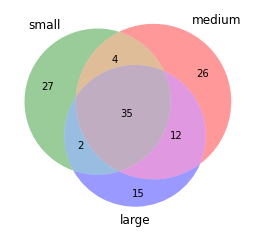

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_venn import venn3


set1 = set(locatif_sm)
set2 = set(locatif_md)
set3 = set(locatif_lg)

venn3([set1, set2, set3], ('small', 'medium', 'large'),set_colors=("green",
                             "red", "blue"))

plt.savefig("Data/%s.png"%"Diagramme sur les EN de {}".format(chanteur))
plt.show()

# faire un dictionnaire d'interrogation permettant de faire des analyses dessus.

In [2]:
#nlp = spacy.load('fr_core_news_sm') #modèle small
#nlp = spacy.load('fr_core_news_md') #modèle medium
#nlp = spacy.load('fr_core_news_lg') #modèle large

modele = ["small", "medium", "large"]
modele_actif = 2

In [81]:
print(chanteur)

_113


In [3]:
import os


dic_interro = {}

if os.path.exists("Data/Dictionnaire_artiste_to_lieux_paris_{}.json".format(modele[modele_actif])):
    with open("Data/Dictionnaire_artiste_to_lieux_paris_{}.json".format(modele[modele_actif]), encoding="UTF-8") as f:
        a = json.load(f)
        for i, c in a.items():
            #print(c[0])
            dic_interro[i] = c
else:
    for nom_artiste, liste_chansons in tqdm.tqdm(corpus2.items()):

      #if nom_artiste == chanteur:
          for element in liste_chansons:
            paroles = element["lyrics"]

            #print(element.keys())
            titre = element["Titre_chanson"]
            try:
                artiste = element["Auteur"]
                #print(type(artiste))
            except:
                artiste = "None"
            try:
                date = element["Date"]
            except:
                date = "None"
            dic_interro.setdefault(nom_artiste, [])
            for txt in paroles:
                if 2>1 :
                    try:
                        doc = nlp(txt)
                        liste_temporaire = []
                        for ent in doc.ents:
                                if ent.label_ == "LOC":
                                    locatif = ent.text
                                    liste_temporaire.append(locatif)
                        if locatif in dic_interro:
                            print("deja dans le dictionnaire") #problème le nom de l'artiste existe deja comment l'ajouter au dictionnaire ?
                        else:
                            #print(type(liste_temporaire[0]))
                            dic_interro[nom_artiste].append([titre, date, liste_temporaire])


                    except:
                        pass

#print(dic_interro)
T = dic_interro.values()
for nom_artiste, T in dic_interro.items():
    #print(T)
    nb_nom_paris = len([x for x in T if len(x[2])==0])
    nb_total_chanson = len(T)
    print(nom_artiste, nb_nom_paris,"nom de lieu cité ")
    print("sur ", nb_total_chanson, "nombre totale de chanson")
    
with open("Data/Dictionnaire_artiste_to_lieux_paris_{}.json".format(modele[modele_actif]), "w") as w:
    w.write(json.dumps(dic_interro, indent=2))

Jacques Dutronc 56 nom de lieu cité 
sur  73 nombre totale de chanson
none 4 nom de lieu cité 
sur  7 nombre totale de chanson
_113 53 nom de lieu cité 
sur  96 nombre totale de chanson
_13Block 56 nom de lieu cité 
sur  112 nombre totale de chanson
_1995 27 nom de lieu cité 
sur  46 nombre totale de chanson
_75èmeSessionxPanamaBendex13Sarkastick 3 nom de lieu cité 
sur  6 nombre totale de chanson
_A2H 125 nom de lieu cité 
sur  199 nombre totale de chanson
_AcidArab 9 nom de lieu cité 
sur  13 nombre totale de chanson
_ACWL 8 nom de lieu cité 
sur  8 nombre totale de chanson
_AdamKesher 3 nom de lieu cité 
sur  5 nombre totale de chanson
_AdolpheBérard 1 nom de lieu cité 
sur  2 nombre totale de chanson
_AdrienGallo 10 nom de lieu cité 
sur  14 nombre totale de chanson
_AdriennePauly 8 nom de lieu cité 
sur  12 nombre totale de chanson
_AfidaTurner 2 nom de lieu cité 
sur  4 nombre totale de chanson
_AgarAgar 9 nom de lieu cité 
sur  19 nombre totale de chanson
_AgnèsBihl 33 nom de li

_DavidKoven 1 nom de lieu cité 
sur  1 nombre totale de chanson
_DavidMartial 1 nom de lieu cité 
sur  1 nombre totale de chanson
_DdeKabal 4 nom de lieu cité 
sur  7 nombre totale de chanson
_DebbieDavis 1 nom de lieu cité 
sur  2 nombre totale de chanson
_DébutDeSoirée 4 nom de lieu cité 
sur  4 nombre totale de chanson
_Deluxe 73 nom de lieu cité 
sur  126 nombre totale de chanson
_Desireless 3 nom de lieu cité 
sur  5 nombre totale de chanson
_Destinity 37 nom de lieu cité 
sur  47 nombre totale de chanson
_Diadem 2 nom de lieu cité 
sur  4 nombre totale de chanson
_Diams 50 nom de lieu cité 
sur  82 nombre totale de chanson
_DickRivers 131 nom de lieu cité 
sur  147 nombre totale de chanson
_DidierBarbelivien 4 nom de lieu cité 
sur  6 nombre totale de chanson
_Didiersuper 31 nom de lieu cité 
sur  45 nombre totale de chanson
_DidierWampas 1 nom de lieu cité 
sur  1 nombre totale de chanson
_Dimiecat 8 nom de lieu cité 
sur  16 nombre totale de chanson
_Dionysos 69 nom de lieu cit

sur  177 nombre totale de chanson
_HubertMounier 3 nom de lieu cité 
sur  4 nombre totale de chanson
_HuguesAufray 133 nom de lieu cité 
sur  158 nombre totale de chanson
_HyphenHyphen 13 nom de lieu cité 
sur  22 nombre totale de chanson
_Hypno5e 24 nom de lieu cité 
sur  40 nombre totale de chanson
_IAM 151 nom de lieu cité 
sur  264 nombre totale de chanson
_Igit 21 nom de lieu cité 
sur  26 nombre totale de chanson
_IlÉtaitUneFois 11 nom de lieu cité 
sur  15 nombre totale de chanson
_IlonaMitrecey 12 nom de lieu cité 
sur  15 nombre totale de chanson
_Imany 23 nom de lieu cité 
sur  36 nombre totale de chanson
_Indila 20 nom de lieu cité 
sur  25 nombre totale de chanson
_Indochine 174 nom de lieu cité 
sur  203 nombre totale de chanson
_IsaacDelusion 19 nom de lieu cité 
sur  32 nombre totale de chanson
_IsabelleAdjani 6 nom de lieu cité 
sur  7 nombre totale de chanson
_IsabelleAubret 4 nom de lieu cité 
sur  4 nombre totale de chanson
_Jackiequartz 1 nom de lieu cité 
sur  1 no

_Les3Ménestrels 1 nom de lieu cité 
sur  1 nombre totale de chanson
_LesAblettes 5 nom de lieu cité 
sur  6 nombre totale de chanson
_LesAvions 6 nom de lieu cité 
sur  7 nombre totale de chanson
_LesCharlots 12 nom de lieu cité 
sur  17 nombre totale de chanson
_LesChatsSauvages 3 nom de lieu cité 
sur  4 nombre totale de chanson
_LesChaussettesNoires 48 nom de lieu cité 
sur  51 nombre totale de chanson
_Lescop 11 nom de lieu cité 
sur  15 nombre totale de chanson
_LesCroquants 24 nom de lieu cité 
sur  27 nombre totale de chanson
_LesElles 22 nom de lieu cité 
sur  25 nombre totale de chanson
_LesForbans 1 nom de lieu cité 
sur  1 nombre totale de chanson
_LesFrangines 3 nom de lieu cité 
sur  3 nombre totale de chanson
_LesHurlementsDLéo 27 nom de lieu cité 
sur  32 nombre totale de chanson
_LesMauvaisesLangues 13 nom de lieu cité 
sur  13 nombre totale de chanson
_LesNégressesVertes 32 nom de lieu cité 
sur  40 nombre totale de chanson
_LesOlivensteins 1 nom de lieu cité 
sur  1 n

_MyriamAbel 22 nom de lieu cité 
sur  24 nombre totale de chanson
_MZ 55 nom de lieu cité 
sur  95 nombre totale de chanson
_Naâman 28 nom de lieu cité 
sur  48 nombre totale de chanson
_Nacash 0 nom de lieu cité 
sur  1 nombre totale de chanson
_NadavGuedjנדבגדג 10 nom de lieu cité 
sur  15 nombre totale de chanson
_Nâdiya 51 nom de lieu cité 
sur  62 nombre totale de chanson
_Naheulband 46 nom de lieu cité 
sur  53 nombre totale de chanson
_Naive 10 nom de lieu cité 
sur  16 nombre totale de chanson
_NajouaBelyzel 38 nom de lieu cité 
sur  47 nombre totale de chanson
_Napkey 3 nom de lieu cité 
sur  3 nombre totale de chanson
_Naps 95 nom de lieu cité 
sur  173 nombre totale de chanson
_Natoo 3 nom de lieu cité 
sur  4 nombre totale de chanson
_NemoSchiffman 1 nom de lieu cité 
sur  4 nombre totale de chanson
_Niagara 39 nom de lieu cité 
sur  45 nombre totale de chanson
_NicolasBacchus 29 nom de lieu cité 
sur  39 nombre totale de chanson
_NicolasKer 0 nom de lieu cité 
sur  1 nombr

sur  3 nombre totale de chanson
_ThePenelopes 1 nom de lieu cité 
sur  1 nombre totale de chanson
_ThePirouettes 49 nom de lieu cité 
sur  60 nombre totale de chanson
_ThierryAmiel 23 nom de lieu cité 
sur  25 nombre totale de chanson
_ThierryCham 8 nom de lieu cité 
sur  9 nombre totale de chanson
_ThierryHazard 5 nom de lieu cité 
sur  12 nombre totale de chanson
_ThierryPastor 1 nom de lieu cité 
sur  2 nombre totale de chanson
_ThomasFersen 102 nom de lieu cité 
sur  128 nombre totale de chanson
_TimDup 20 nom de lieu cité 
sur  27 nombre totale de chanson
_TinoRossi 41 nom de lieu cité 
sur  52 nombre totale de chanson
_TomFrager 6 nom de lieu cité 
sur  13 nombre totale de chanson
_TomLeeb 2 nom de lieu cité 
sur  3 nombre totale de chanson
_TomPoisson 21 nom de lieu cité 
sur  24 nombre totale de chanson
_Trisomie21 2 nom de lieu cité 
sur  2 nombre totale de chanson
_TriYann 40 nom de lieu cité 
sur  69 nombre totale de chanson
_TroisCafésGourmands 3 nom de lieu cité 
sur  3 no

# Créer un graph des artistes parlant du + "x".
x = un lieu de paris. 
somme globale. = pour un lieu qui est l'auteur qui a le plus parlé?

In [204]:
#print(dic_interro)

{'Jacques Dutronc': [['Mini, Mini, Mini by\xa0Jacques\xa0Dutronc', None, ['Maxitère']], ['Et Moi, Et Moi, Et Moi by\xa0Jacques\xa0Dutronc', None, ['Canigou']], ['Les Cactus by\xa0Jacques\xa0Dutronc', None, []], ['Fais Pas Ci, Fais Pas Ça by\xa0Jacques\xa0Dutronc', None, []], ["Il Est Cinq Heures, Paris S'Eveille by\xa0Jacques\xa0Dutronc", None, []], ["J'aime les filles by\xa0Jacques\xa0Dutronc", '1967-01-01', ['Mégève', 'Saint-Tropez', 'la Rochelle', 'Camaret \n ', 'France']], ['Les Playboys by\xa0Jacques\xa0Dutronc', None, []], ['Hippie Hippie Hourrah by\xa0Jacques\xa0Dutronc', None, ['San Francisco', 'la France']], ["L'Opportuniste by\xa0Jacques\xa0Dutronc", None, []], ['La Fille Du Père Noël by\xa0Jacques\xa0Dutronc', None, []], ['Le Responsable by\xa0Jacques\xa0Dutronc', None, ["Parc'"]], ['On Nous Cache Tout, On Nous Dit Rien by\xa0Jacques\xa0Dutronc', None, ['Est', 'Obélisque']], ["L'Idole (Je N'En Peux Plus) by\xa0Jacques\xa0Dutronc", None, []], ['La Métaphore by\xa0Jacques\xa0D

In [4]:
#somme globale. = pour un lieu qui est l'auteur qui a le plus parlé?
    #print()
dico_des_artistes = {}
"""dico_des_artistes['Tiago'] = {}
dico_des_artistes['Tiago']['Mini-moke'] = 3
dico_des_artistes['Tiago']['Place de Clichy'] = 20
dico_des_artistes['dygor'] = {}
dico_des_artistes['dygor']['Mini-moke'] = 40
dico_des_artistes['dygor']['Place de Clichy'] = 15
dico_des_artistes['Ulysse'] = {}
dico_des_artistes['Ulysse']['Mini-moke'] = 5
dico_des_artistes['Ulysse']['non'] = 2
dico_des_artistes['k'] = {}
dico_des_artistes['k']['Mini-moke'] = 2
dico_des_artistes['k']['Place de Clichy'] = 5"""

if os.path.exists("Data/Dictionnaire_des_artistes_{}.json".format(modele[modele_actif])):
    with open("Data/Dictionnaire_des_artistes_{}.json".format(modele[modele_actif]), encoding="UTF-8") as f:
        a = json.load(f)
        for i, c in a.items():
            #print(c[0])
            dico_des_artistes[i] = c
else:
    for cle,valeur in dic_interro.items():
        #print(cle)
        
        dico_en = {}
        for i in range(len(valeur)):
            #print(valeur[i][2])
            for entite in valeur[i][2]:
                z = str(entite)
                #print(type(z))
                if z not in dico_en:
                    dico_en[z]=1
                else:
                    dico_en[z]+=1
        dico_des_artistes[cle]=dico_en
dico_des_artistes
with open("Data/Dictionnaire_des_artistes_{}.json".format(modele[modele_actif]), "w") as w:
    w.write(json.dumps(dico_des_artistes, indent=2))



In [210]:
print(json.dumps(dico_des_artistes, indent=2))

{
  "Jacques Dutronc": {
    "Maxit\u00e8re": 1,
    "Canigou": 1,
    "M\u00e9g\u00e8ve": 1,
    "Saint-Tropez": 1,
    "la Rochelle": 1,
    "Camaret \n ": 1,
    "France": 1,
    "San Francisco": 1,
    "la France": 2,
    "Parc'": 1,
    "Est": 1,
    "Ob\u00e9lisque": 1,
    "Val-de-Gr\u00e2ce": 1,
    "Varsovie": 2,
    "Baltimore": 2,
    "Yaound\u00e9": 1,
    "Amsterdam": 1,
    "Born\u00e9o": 1,
    "Papeete": 1,
    "Bordeaux": 1,
    "Tampico": 1,
    "Calcutta": 1,
    "T\u00e9h\u00e9ran": 1,
    "Saana": 1,
    "Cotonou": 1,
    "D\u00f4le": 1,
    "Lourdes": 1,
    "Cr\u00e9teil": 1,
    "Port-Gentil": 1,
    "Tripoli": 1,
    "Ak\u00e9k\u00e9": 1,
    "Ak\u00e9k\u00e9k\u00e9": 1,
    "Ak\u00e9k\u00e9k\u00e9k\u00e9": 1,
    "Aidez": 2,
    "J'ai Maginot": 1,
    "Bouquin'": 1,
    "Amiens": 1,
    "Paris": 1,
    "He!He": 1,
    "Oh!Ooh!Quand": 1,
    "J'habite rue Le Regrantier": 1,
    "V\u00e9nus": 1,
    "Milo": 1,
    "P\u00e9tuchet": 1,
    "Millau": 1,
    "Bernha

# Pour un lieux quel artiste en parle

In [ ]:
#test
"""e = "Mini-moke"
for cle, valeur in dico_des_artistes.items():
    test = dico_des_artistes[cle]
    #print(type(test))
    for c, v in test.items():
        if c == e:
            tograph[cle] = v
print(tograph)"""

In [8]:
import re
#print(dico_des_artistes['Jacques Dutronc'])

tograph = {}


def Chercherlieux(un_lieu):
    l = un_lieu
    tograph[l] = {}
    for cle, valeur in dico_des_artistes.items():
        dico_du_dico = dico_des_artistes[cle]
        for c, v in dico_du_dico.items():
            if c == un_lieu:
                tograph[l][cle] = v
    return tograph[l]



Chercherlieux("Place de Clichy")
Chercherlieux("Créteil")
Chercherlieux("Saint-Tropez")
Chercherlieux("Paris")
Chercherlieux("Lilas")

{'_BillDeraime': 1,
 '_DamienSaez': 1,
 '_FrancisCabrel': 1,
 '_GauvainSers': 2,
 '_GeorgesBrassens': 2,
 '_GuyBéart': 1,
 '_JacquelineFrançois': 1,
 '_JulietteGréco': 1,
 '_Sefyu': 1}

In [ ]:
#a faire chercher les lieux qui commence par place

In [9]:
#print(tograph)

tograph_trier = {}
for lieu, valeur in tograph.items():
    #g = tograph[lieu]
    #print(g)
    #print(lieu, valeur)
    tograph_trier[lieu] = {}
    for artiste, frequence in sorted(valeur.items(), key=lambda x: x[1], reverse=True):
        tograph_trier[lieu][artiste] = frequence
#print(tograph_trier)
for lieu2 , valeur in tograph_trier.items():
    for artiste, frequence in valeur.items():
        cinq_premier_lieux = [k for k in valeur.keys()][:5]
        cinq_premier_frequence = [k for k in valeur.values()][:5]
        print(cinq_premier_frequence, cinq_premier_lieux, frequence)
        break
            
    #g = tograph_trier[cle]
    #print(g)

[1, 1, 1, 1, 1] ['Jacques Dutronc', '_DidierBarbelivien', '_JacquesDutronc', '_JohnnyHallyday', '_Renaud'] 1
[1, 1, 1, 1, 1] ['Jacques Dutronc', '_DanyBrillant', '_Gradur', '_JacquesDutronc', '_SergeGainsbourg'] 1
[47, 40, 36, 31, 30] ['_A2H', '_Rouda', '_JoeDassin', '_CharlesAznavour', '_LéoFerré'] 47
[2, 2, 1, 1, 1] ['_GauvainSers', '_GeorgesBrassens', '_BillDeraime', '_DamienSaez', '_FrancisCabrel'] 2


In [482]:
print(tograph_trier)

{'Place de Clichy': {}, 'Créteil': {'Jacques Dutronc': 1, '_DidierBarbelivien': 1, '_JacquesDutronc': 1, '_JohnnyHallyday': 1, '_Renaud': 1}, 'Saint-Tropez': {'Jacques Dutronc': 1, '_DanyBrillant': 1, '_Gradur': 1, '_JacquesDutronc': 1, '_SergeGainsbourg': 1}, 'Paris': {'_A2H': 47, '_Rouda': 40, '_JoeDassin': 36, '_CharlesAznavour': 31, '_LéoFerré': 30, '_Renaud': 30, '_TSRCrew': 30, '_DamienSaez': 29, '_Guizmo': 29, '_Kaaris': 28, '_CharlesTrenet': 27, '_ManoSolo': 27, '_ÉdithPiaf': 25, '_MichelDelpech': 25, '_Sofiane': 25, '_ÉmilieSimon': 23, '_JeanFerrat': 22, '_CyrilMokaiesh': 21, '_JulienClerc': 21, '_JulietteGréco': 20, '_BernardLavilliers': 19, '_LuisMariano': 19, '_YvesMontand': 19, '_JosephineBaker': 18, '_JulienDoré': 17, '_LaFouine': 17, '_TaxiGirl': 17, '_Alkpote': 15, '_ChristopheMaé': 15, '_ÉtienneDaho': 15, '_TêtesRaides': 15, '_EddyMitchell': 14, '_JeanJacquesDebout': 14, '_Natoo': 14, '_MarcLavoine': 13, '_BenMazué': 12, '_FranceGall': 12, '_GeorgesBrassens': 12, '_Gue

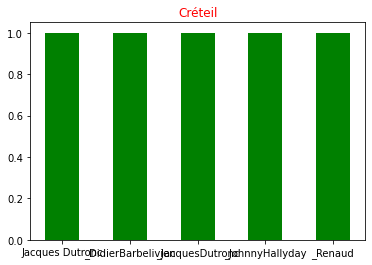

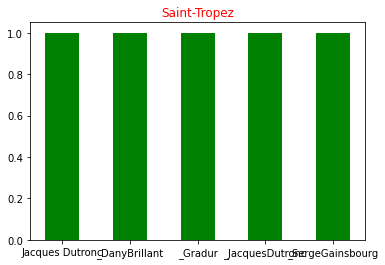

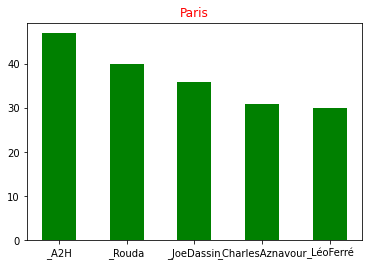

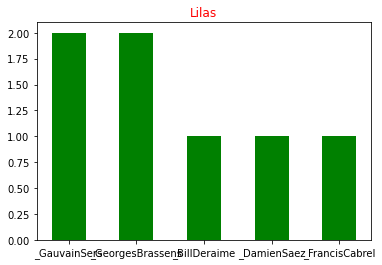

In [10]:
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure()
for lieu2 , valeur in tograph_trier.items():
    for artiste, frequence in valeur.items():
        #if artiste <= 5:
        if 2 > 1:
            #print(lieu2, frequence)
            #g = tograph_trier[cle]
            y = cinq_premier_frequence = [k for k in valeur.values()][:5]
            x = cinq_premier_lieux = [k for k in valeur.keys()][:5]
            width = 0.50
            #x2 = plt.xlabel(x,color="r")
            #plt.ylabel(height,color="r")
            plt.title(lieu2, color='r')
            plt.bar(x, y, width, color='green')

            plt.savefig('Data/image_large/%s.png'%lieu2)
            plt.show()
            break

# Pour chaque lieux calculer sa fréquence dans le corpus¶

In [11]:
for lieu, dico in tograph.items():
    total_apparition_corpus = 0
    for artiste, apparition in dico.items():
        total_apparition_corpus += apparition
       #print(lieu, total_apparition_corpus)
    print(lieu, total_apparition_corpus)

Place de Clichy 0
Créteil 5
Saint-Tropez 5
Paris 1639
Lilas 11


In [ ]:
#pour le pourcentage des lieux de paris.
#somme a l'interieur d'un auteur = exemple 80% des EN sont des lieux de paris.
#somme globale. = pour un lieu qui est l'auteur qui a le plus parlé?

# le lieu le plus fréquent pr un artiste

In [5]:
#somme globale. = pour un lieu qui est l'auteur qui a le plus parlé?
    #print()
dico_des_lieux = {}


for cle, valeur in dic_interro.items():
    #dico_en = {}
    for i in range(len(valeur)):
        dico_tempo = {}
        for entite in valeur[i][2]:
            #print(entite)
            dico_des_lieux.setdefault(entite, {})
            dico_des_lieux[entite].setdefault(cle, 0)
            dico_des_lieux[entite][cle]+=1
            
with open("Data/Dictionnaire_lieux_paris_{}.json".format(modele[modele_actif]), "w") as w:
    w.write(json.dumps(dico_des_lieux, indent=2))

#print(dico_des_lieux)

In [13]:
tograph2 = {}
def ChercherArtiste(nom_artiste):
    l = nom_artiste
    tograph2[l] = {}
    for cle, valeur in dico_des_lieux.items():
        if cle in vrai_entite_nomme:
            dico_du_dico = dico_des_lieux[cle]
            for c, v in dico_du_dico.items():
                if c == l:
                    tograph2[l][cle] = v
    return tograph2[l]
ChercherArtiste("_JoeDassin")

{'Paris': 36,
 'Tour Eiffel': 1,
 'Clignancourt': 2,
 'Opéra': 2,
 'Amérique': 1,
 'Clichy': 2,
 'Pologne': 3,
 'Luxembourg': 1}

In [14]:
tograph2_trier = {}
#count = 0
for cle, valeur in tograph2.items():
    g = tograph2[cle]
    #print(g.values())
    for artiste, frequence in sorted(valeur.items(), key=lambda x: x[1], reverse=True):
        tograph2_trier[artiste] = frequence
        
cinq_premier_lieux = [k for k in tograph2_trier.keys()][:5]
#print(premier_lieux)
        #count += 1
#print(tograph2)
print(tograph2_trier)

#code a modifier pour récuperer les 5 premières valeur du dic.

{'Paris': 36, 'Pologne': 3, 'Clignancourt': 2, 'Opéra': 2, 'Clichy': 2, 'Tour Eiffel': 1, 'Amérique': 1, 'Luxembourg': 1}


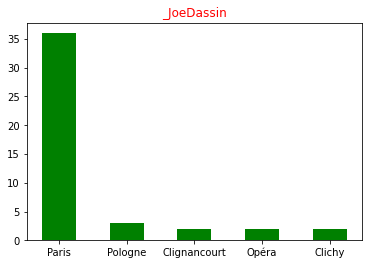

In [15]:
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure()
for cle, valeur in tograph2.items():
#if 2>0:
    cinq_premier_lieux_item = [k for k in tograph2_trier.items()][:5]
    cinq_premier_lieux_keys = [k for k in tograph2_trier.keys()][:5]
    cinq_premier_lieux_values = [k for k in tograph2_trier.values()][:5]
    g = cinq_premier_lieux
    x = cinq_premier_lieux_keys
    height = cinq_premier_lieux_values
    width = 0.50
    #x2 = plt.xlabel(x,color="r")
    #plt.ylabel(height,color="r")
    plt.title(cle, color='r')
    plt.bar(x, height, width, color='green')
    
    plt.savefig('Data/image_{}/{}.png'.format(modele[modele_actif],cle))
    plt.show()       


In [6]:
dic_interro_des_lieux = {}
#print(dic_interro.items())
if os.path.exists("Data/Dictionnaire_interro_lieux_paris_{}.json".format(modele[modele_actif])):
    with open("Data/Dictionnaire_interro_lieux_paris_{}.json".format(modele[modele_actif]), encoding="UTF-8") as f:
        dic_interro_des_lieux = json.load(f)
else:
    for artiste, valeur in dic_interro.items():
        for i in range(len(valeur)):
            #print(valeur[i][0]) #titre
            #print(valeur[i][2]) #entité
            #print(valeur[i][1]) #date
            for entite in valeur[i][2]:
                dic_interro_des_lieux.setdefault(entite, {})
                dic_interro_des_lieux[entite].setdefault(artiste, [])
                dic_interro_des_lieux[entite][artiste].append([valeur[i][0],valeur[i][1]])
#print(dic_interro_des_lieux)
            
with open("Data/Dictionnaire_interro_lieux_paris_{}.json".format(modele[modele_actif]), "w") as w:
    w.write(json.dumps(dic_interro_des_lieux, indent=2)) 
    

In [175]:
print(json.dumps(dic_interro_des_lieux, indent=2))

IOPub data rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_data_rate_limit`.

Current values:
NotebookApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
NotebookApp.rate_limit_window=3.0 (secs)



In [18]:

def infolieu():
    cpt = 0 
    recherche = input()
    for lieu, dico in dic_interro_des_lieux.items():
        if lieu == recherche:
        #print(dico.items())

            for artiste, valeur in dico.items():
                #print(valeur[0][1]) #date
                #print(valeur[0][0]) #titre
                for i in valeur:
                    #continue
                    cpt += 1
                    print(lieu, "\t",artiste,"\t", i, cpt)
    return None
infolieu()

Trappes
Trappes 	 _Booba 	 ['A.C. Milan by\xa0Booba', '2013-01-21'] 1
Trappes 	 _Guizmo 	 ['Guizmo - Partiel de Punchline by\xa0Guizmo', None] 2
Trappes 	 _Kamelancien 	 ['Crise Cardiaque (clash La Fouine) by\xa0Kamelancien', None] 3
Trappes 	 _Kamelancien 	 ['Crise Cardiaque (clash La Fouine) by\xa0Kamelancien', None] 4
Trappes 	 _LaFouine 	 ['Veni, vidi, vici by\xa0La\xa0Fouine', '2010-12-10'] 5
Trappes 	 _LaFouine 	 ["On s'en bat les couilles 2013 by\xa0La\xa0Fouine (Ft.\xa0Mac\xa0Tyer)", '2013-02-04'] 6
Trappes 	 _LaFouine 	 ["D'où l'on vient by\xa0La\xa0Fouine", '2011-01-19'] 7
Trappes 	 _LaFouine 	 ['Reste en chien by\xa0La\xa0Fouine (Ft.\xa0Booba)', '2007-03-12'] 8
Trappes 	 _LaFouine 	 ["J'espère by\xa0La\xa0Fouine", '2013-02-04'] 9
Trappes 	 _LaFouine 	 ['Elle venait du ciel by\xa0La\xa0Fouine (Ft.\xa0Zaho)', '2011-02-14'] 10
Trappes 	 _LaFouine 	 ['Bafana Bafana - Remix by\xa0La\xa0Fouine (Ft.\xa0Admiral\xa0T, Canardo, Nessbeal, Seth\xa0Gueko & Soprano)', '2011-02-14'] 11
Tra

In [19]:
dic_for_date = {}

for nom_artiste, valeur in dic_interro.items():
    for x in valeur:
        titre = x[0]
        date = x[1]
        if date != None:
            dic_for_date.setdefault(date, [])
            for lieu in x[2]:
                #print(lieu)
                if lieu in vrai_entite_nomme:
                    #print(lieu)
                    dic_for_date[date].append([lieu, titre])
        #print(x[1]) #Date
print(dic_for_date)

{'1967-01-01': [['Sorbonne', 'Ils se sont dit: « Je t’aime » by\xa0Jehan\xa0Jonas']], '1980-01-01': [], '2005-10-19': [['Paris', 'Grandir avec ça by\xa0113 (Ft.\xa0Djam\xa0El)'], ['Paris', 'Grandir avec ça by\xa0113 (Ft.\xa0Djam\xa0El)']], '2006-04-10': [['Tour Eiffel', 'Avec le punch by\xa0113']], '2005-11-14': [], '1999-10-26': [], '2010-12-06': [['Paris', 'Dubaï by\xa0113 (Ft.\xa0Cheb\xa0Bilal الشاب بلال)'], ['Europe', 'On Va Décoller by\xa0113 (Ft.\xa0Magic\xa0System)'], ['Seine', 'Je ne serai jamais ta Parisienne by\xa0Nolwenn\xa0Leroy']], '2005-02-20': [['Paris', "On sait l'faire by\xa0113 (Ft.\xa0Booba & Le\xa0Rat Luciano)"]], '2003-01-01': [['Paris', "Rabzouz by\xa0Mafia\xa0K'1 Fry"], ['Paris', "Rabzouz by\xa0Mafia\xa0K'1 Fry"], ['Paris', "Rabzouz by\xa0Mafia\xa0K'1 Fry"], ['Paris', "Rabzouz by\xa0Mafia\xa0K'1 Fry"]], '2002-05-04': [], '2009-06-29': [['Paris', 'Célébration by\xa0113 (Ft.\xa0Awa\xa0Imani & Jamel\xa0Debbouze)']], '1999-10-27': [['Seine', 'Main dans la main by\xa0

In [179]:
import re

dictionnaire = {}          
def find_lieu_titre_par_annee(annee, dictionnaire):
    years = r"%s-\d\d-\d\d"%annee
    for date, valeur in dic_for_date.items():
        match = re.search(years, date)
        if match:
            dictionnaire.setdefault(annee, {})
            for x in valeur:
                lieu = x[0]
                dictionnaire[annee].setdefault(lieu, 0)
                dictionnaire[annee][lieu] += 1
    return dictionnaire



In [180]:
observation = {}
cpt = 1950

while cpt <= 2000:
    print(find_lieu_titre_par_annee(cpt, observation))
    cpt += 1

{1950: {}}
{1950: {}, 1951: {}}
{1950: {}, 1951: {}, 1952: {'Gare': 1, 'Versailles': 1}}
{1950: {}, 1951: {}, 1952: {'Gare': 1, 'Versailles': 1}, 1953: {}}
{1950: {}, 1951: {}, 1952: {'Gare': 1, 'Versailles': 1}, 1953: {}, 1954: {'Pontoise': 1}}
{1950: {}, 1951: {}, 1952: {'Gare': 1, 'Versailles': 1}, 1953: {}, 1954: {'Pontoise': 1}, 1955: {}}
{1950: {}, 1951: {}, 1952: {'Gare': 1, 'Versailles': 1}, 1953: {}, 1954: {'Pontoise': 1}, 1955: {}, 1956: {}}
{1950: {}, 1951: {}, 1952: {'Gare': 1, 'Versailles': 1}, 1953: {}, 1954: {'Pontoise': 1}, 1955: {}, 1956: {}, 1957: {}}
{1950: {}, 1951: {}, 1952: {'Gare': 1, 'Versailles': 1}, 1953: {}, 1954: {'Pontoise': 1}, 1955: {}, 1956: {}, 1957: {}, 1958: {}}
{1950: {}, 1951: {}, 1952: {'Gare': 1, 'Versailles': 1}, 1953: {}, 1954: {'Pontoise': 1}, 1955: {}, 1956: {}, 1957: {}, 1958: {}, 1959: {'Invalides': 1}}
{1950: {}, 1951: {}, 1952: {'Gare': 1, 'Versailles': 1}, 1953: {}, 1954: {'Pontoise': 1}, 1955: {}, 1956: {}, 1957: {}, 1958: {}, 1959: {'In

In [193]:
tograph3 = {}
find_lieu_titre_par_annee(2010, tograph3)

{2010: {'Paris': 13,
  'Europe': 1,
  'Seine': 1,
  'Courcouronnes': 2,
  'Fresnes': 8,
  'Trappes': 6,
  'rue des Batignolles': 1,
  'boulevard des Batignolles': 1,
  'rue de Berne': 1,
  'rue de Rome': 1,
  'Amérique': 3,
  'Pologne': 1,
  'Tour Eiffel': 2,
  'Versailles': 7,
  'Osny': 1}}

In [194]:
freq = []
lieu = []


for date, valeur in tograph3.items():
    toto = sorted([[freq, nom] for nom,freq in valeur.items()], reverse=True)
    for i in range(len(toto)):
        freq.append(toto[i][0])
        lieu.append(toto[i][1])

print(toto)
print(freq)
print(lieu)
    #cinq_premier_lieux_values = toto[:5]
    #print(cinq_premier_lieux_values)

[[13, 'Paris'], [8, 'Fresnes'], [7, 'Versailles'], [6, 'Trappes'], [3, 'Amérique'], [2, 'Tour Eiffel'], [2, 'Courcouronnes'], [1, 'rue des Batignolles'], [1, 'rue de Rome'], [1, 'rue de Berne'], [1, 'boulevard des Batignolles'], [1, 'Seine'], [1, 'Pologne'], [1, 'Osny'], [1, 'Europe']]
[13, 8, 7, 6, 3, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1]
['Paris', 'Fresnes', 'Versailles', 'Trappes', 'Amérique', 'Tour Eiffel', 'Courcouronnes', 'rue des Batignolles', 'rue de Rome', 'rue de Berne', 'boulevard des Batignolles', 'Seine', 'Pologne', 'Osny', 'Europe']


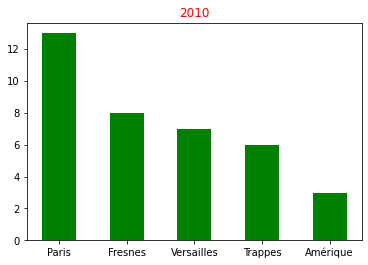

In [195]:
#fig = plt.figure()
import matplotlib.pyplot as plt
import numpy as np
x = [x for x in lieu][:5]
height = [x for x in freq][:5]
width = 0.50
    #x2 = plt.xlabel(x,color="r")
    #plt.ylabel(height,color="r")
plt.title(date, color='r')
plt.bar(x, height, width, color='green')

plt.savefig('Data/image_{}/{}.png'.format(modele[modele_actif],date))
plt.show()       

# Un code qui propose le lieu detecter par spacy et l'ajoute dans le corpus lieux de paris pour le compléter.

In [77]:
tous_les_locatifs = []

for lieux in locatif_sm:
    tous_les_locatifs.append(lieux)
#print(lieux_des_3_modèles)
for lieux in locatif_md:
    tous_les_locatifs.append(lieux)
for lieux in locatif_lg:
    tous_les_locatifs.append(lieux)   
lieux_des_3_modèles = set(tous_les_locatifs)
#print(lieux_des_3_modèles)

with open("Data/Tous_les_lieux_paris_detecte.json", "w") as w:
    w.write(json.dumps(tous_les_locatifs))

In [ ]:
oui = "oui"
non = "non"
fini = "stop"
dictionnaire_to_corpus_lieux = {}

for lieux in lieux_des_3_modèles:
    if lieux not in vrai_entite_nomme:
        ajout_dans_corpus = input("""Ce lieux "%s" est-il un lieux de paris ? Répondez par oui/non :""" %lieux)
        if ajout_dans_corpus == oui:
            dictionnaire_to_corpus_lieux.setdefault(lieux, [])
            precision = input("Ce lieux possède t'il d'autre nom que vous connaissez? Répondez par oui/non :")
            autre_nom = []
            if precision == oui:
                nom = input("""insérez les autres nom, sinon écrivez "stop" pour arreter :""")
                autre_nom.append(nom)
                while nom != fini:
                    nom = input("""insérez un autres nom, sinon écrivez "stop" pour arreter :""")
                    autre_nom.append(nom)
                autre_nom.pop(-1)
                dictionnaire_to_corpus_lieux[lieux].append(autre_nom)
                    #faire répéter la commande autant de fois jusqu'a ce qu'il disent non.
            if precision == non:
                dictionnaire_to_corpus_lieux[lieux].append(None)
                continue
        if ajout_dans_corpus == non:
            pass
with open("Data/Dictionnaire lieux implémenté.json", "w") as w:

    w.write(json.dumps(dictionnaire_to_corpus_lieux, indent=2))

In [ ]:
#sur quelque texte faire une sortie ou chaque token du txt et l'étiquette donner par spacy 

# Statistique sur les mots qui sont avant le lieu

In [21]:
for lieu, valeur in dic_interro_des_lieux.items():
    for artiste, liste in valeur.items():
        date = liste[0][1] #date
        titre = liste[0][0] #titre
        print(date)

None
None
None
2015-03-02
None
None
1967-01-01
1967-01-01
1967-01-01
1999-04-20
2019-11-29
1967-01-01
1973-11-16
1967-01-01
1965-01-01
1967-01-01
None
1967-01-01
1967-01-01
1967-01-01
1998-01-01
2017-12-08
2012-03-05
2008-05-12
None
None
2012-06-02
None
1997-07-13
2017-12-01
None
2013-09-25
None
2017-12-01
None
2016-02-26
2019-06-24
None
None
None
None
None
2017-01-20
2018-10-05
1999-10-25
None
None
None
2015-04-15
2015-12-29
2010-10-18
None
2020-08-14
2010-01-01
2019-01-11
2020-12-12
None
1998-01-13
None
None
1976-12-01
None
None
None
2011-10-03
None
2017-04-14
None
1967-01-01
None
None
1968-01-01
None
None
None
2013-10-21
2018-11-23
None
2017-01-27
2012-12-06
2014-09-29
None
None
2002-10-07
2018-02-15
2014-05-17
2017-12-20
2006-01-26
None
None
2007-01-29
None
None
2017-11-03
None
None
2019-01-30
2016-04-22
2015-10-30
2017-10-06
None
2019-02-28
1996-11-11
2002-09-03
2011-09-15
None
None
None
1975-04-03
None
None
None
2020-07-24
None
None
2011-11-21
2010-10-04
1995-02-13
None
None
None

2012-03-19
None
None
1999-01-01
None
2013-11-25
None
2019-05-31
None
None
2018-07-05
2016-05-13
None
2017-03-10
None
2012-01-01
1996-11-19
None
None
None
2016-06-03
None
2019-01-25
None
None
None
None
2017-07-07
None
2011-02-14
None
2019-01-10
None
None
2000-09-28
None
None
1999-08-31
None
None
None
None
2010-12-06
None
None
2019-04-12
2003-09-15
None
1998-04-21
None
None
None
1998-01-01
2016-06-24
2019-11-15
2017-10-14
2014-12-05
2015-03-29
1998-01-01
2019-03-22
2015-09-25
1998-01-01
2012-03-05
2016-04-15
2012-11-26
None
2017-03-03
None
None
2007-01-01
2017-12-20
2008-05-19
None
None
None
None
1998-01-01
2018-05-25
None
2005-12-01
None
2014-09-15
None
None
None
1998-01-01
None
None
2017-06-24
None
2019-12-20
2010-05-28
None
2007-11-20
2018-10-12
None
2019-01-11
None
None
1995-01-01
2018-06-22
None
2019-06-28
2017-09-22
2006-10-15
None
None
None
None
None
None
2017-05-12
None
2020-11-30
2017-09-20
2017-01-28
2019-04-14
2014-03-15
1972-01-01
None
2020-01-13
2014-11-24
None
None
2015-10-

2017-02-10
2009-04-14
2013-05-02
2016-06-13
None
None
2019-06-21
None
None
None
None
2015-12-09
None
2020-12-11
2010-05-28
None
None
None
2015-10-01
2008-01-01
2009-04-12
None
None
None
None
None
2018-03-09
2017-12-20
2020-01-28
2014-01-01
2015-04-12
None
None
None
2018-03-02
2018-04-06
1997-03-18
None
2011-01-01
2005-12-19
None
None
None
2020-06-12
None
None
None
None
None
None
None
None
2014-11-21
2015-03-04
None
None
2017-03-03
None
2018-03-16
None
2019-11-15
2019-09-20
2017-10-30
2020-05-15
2011-06-15
2019-10-15
2013-02-04
None
None
2010-07-05
2017-10-06
None
None
2014-09-15
2018-11-09
None
None
2015-08-07
2013-03-26
2018-04-12
2017-03-08
2014-11-14
1991-04-01
None
2019-02-15
2017-09-29
None
1989-01-01
None
None
2017-11-03
None
None
None
None
None
None
None
None
2008-12-01
None
2016-06-10
None
2016-04-22
None
2016-03-01
None
2020-03-07
2018-04-27
None
None
2007-04-03
2017-10-20
2018-01-11
2016-07-01
None
None
2017-02-24
2014-03-15
2008-04-13
None
2005-02-24
None
None
None
1971-03-2

None
2017-05-19
None
None
2017-02-05
None
None
None
2003-04-28
None
None
None
None
None
None
None
None
None
None
2006-11-18
2016-04-15
None
None
None
None
None
None
None
None
2007-11-19
None
None
2020-11-20
None
None
None
None
None
None
None
2018-11-28
None
None
1954-01-01
None
None
None
None
None
None
None
None
None
None
None
2004-10-27
None
1975-04-03
2008-05-12
None
None
2019-10-10
1999-01-01
None
None
2017-05-12
None
1993-11-09
2018-10-12
None
2005-09-05
2005-09-05
2005-09-05
None
None
2019-04-12
None
None
None
1983-01-01
None
2007-11-19
2000-01-01
None
None
None
None
None
None
None
None
2010-12-06
None
None
None
None
None
None
None
None
2018-02-02
2010-12-06
None
None
None
1976-01-01
None
None
2019-07-05
None
None
None
None
2014-02-24
None
2008-01-22
None
None
None
None
None
2012-11-26
2017-12-01
None
2017-01-20
2020-04-03
None
None
None
None
2011-04-23
None
None
None
None
None
2012-04-27
None
1999-01-01
None
1985-01-01
None
1993-11-22
1997-07-07
None
1985-01-01
1985-01-01
2006-11

2018-10-05
2020-11-13
2017-11-14
2019-09-13
2019-05-16
2018-07-19
None
2019-07-05
None
2019-11-15
2014-02-24
2020-10-09
2019-04-19
2019-06-28
2019-06-21
None
2020-09-30
2019-11-08
2018-10-05
2020-02-21
2016-01-01
2014-04-28
None
2018-10-05
None
2017-09-01
2017-10-20
None
1990-01-01
None
2017-09-29
None
None
None
2000-09-12
1990-01-01
None
None
2016-07-15
None
1990-01-01
2019-01-18
2019-11-29
None
None
2005-12-05
2017-01-20
1990-01-01
None
2016-11-18
2016-11-18
2009-02-16
2020-04-19
None
None
2014-01-01
None
None
2004-08-09
None
2016-11-18
None
None
None
2019-09-27
1969-01-01
1961-01-01
1994-01-01
2010-03-29
None
2007-10-29
None
None
None
2018-01-22
1968-01-01
1997-01-01
1981-01-01
1994-01-01
1994-01-01
2000-10-31
1998-01-01
1998-01-01
1998-01-01
1997-01-01
1968-01-01
None
None
None
1998-01-13
None
2020-10-23
2016-11-04
None
2018-03-09
None
2016-05-02
None
None
2020-11-29
2020-11-29
2020-11-29
None
2020-11-29
2020-11-29
None
2020-11-29
2019-02-10
2019-02-10
None
2019-02-10
2019-02-10
20

...

None
2020-01-23
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
1988-05-02
None
2015-11-27
None
2020-10-23
None
2018-03-30
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
2005-05-23
None
None
None
None
None
None
None
None
2020-05-29
2020-05-29
2020-06-12
2018-04-20
2020-06-26
2020-06-12
2005-04-26
2015-04-16
2020-06-12
2019-12-06
None
2017-11-10
None
None
2019-04-05
2015-02-16
2015-02-16
None
None
None
None
None
2012-04-01
2002-09-03
None
None
None
None
2019-10-10
2019-10-10
2019-10-10
2019-10-10
2019-10-10
2019-10-10
2019-10-10
2019-10-10
2019-10-10
2019-10-10
2019-10-10
None
None
2018-12-07
None
None
None
2003-12-01
2009-04-12
2011-01-17
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
1984-10-02
None
None
None
2007-02-19
1962-12-01
None
1952-11-05
None
1952-11-05
None
None
None
None
None
2019-01-25
None
2018-01-26
None
1966-04-07
None
None
None
None
None
None
None
1997-

None
None
None
2019-01-10
2016-03-11
None
None
None
1995-06-19
None
None
None
None
2007-03-12
2006-04-24
None
None
None
None
None
None
2011-03-28
None
None
None
None
1976-11-07
None
None
None
None
None
None
None
None
None
None
None
None
None
None
2010-10-04
None
None
None
None
None
None
1992-12-08
2019-11-22
None
None
2017-10-05
2021-03-19
2012-10-08
None
None
None
2005-10-03
None
None
None
None
2003-05-20
2003-05-20
2003-05-20
None
None
None
None
None
None
None
None
2008-09-16
None
2010-12-06
None
None
None
None
None
None
None
None
None
None
2003-05-20
None
2003-05-20
None
2020-12-01
None
None
None
None
None
2013-10-28
None
None
None
None
None
None
None
2016-11-11
2018-03-02
2020-09-04
None
None
2011-03-21
2018-03-02
1991-01-01
2002-11-12
None
2008-06-16
2018-11-16
None
2008-06-16
1976-11-18
2013-10-23
2011-03-21
None
2011-03-21
2011-03-21
2011-03-21
None
2011-03-21
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
2013-

None
2018-03-30
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
2016-02-19
None
None
1976-01-01
2016-02-19
2016-02-19
2016-02-19
2016-02-19
None
2016-02-19
2016-02-19
2016-02-19
2016-02-19
2016-02-19
2016-02-19
2016-02-19
2016-02-19
2016-02-19
2016-02-19
2007-08-31
None
2018-12-10
2018-12-10
2010-07-05
2009-02-20
2009-02-20
2009-02-20
2009-02-20
2009-02-20
2009-02-20
None
2009-02-20
2009-02-20
2008-08-06
2007-12-26
2008-08-06
2009-02-20
2009-02-20
2017-10-20
2008-08-06
2008-08-06
2007-12-26
2008-08-06
2009-02-20
2009-02-20
2010-07-05
None
None
None
None
1961-04-05
None
None
None
None
None
2018-03-30
2019-04-12
None
None
1974-01-01
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
1981-11-17
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
Non

2004-03-26
2004-03-26
2002-09-03
2002-09-03
2002-09-03
2002-09-03
2004-10-27
2004-10-27
2004-10-27
2004-10-27
2004-10-27
2004-10-27
2004-10-27
2004-10-27
2004-10-27
2002-09-03
2002-09-03
2018-11-09
2007-03-26
2007-03-26
2004-10-27
2004-10-27
2004-10-27
2002-09-03
2007-03-26
2004-10-27
2002-09-03
2002-09-03
2004-10-27
None
2002-09-03
2002-09-03
2002-09-03
2000-11-20
2000-11-20
2000-11-20
2000-11-20
2012-03-22
2012-03-22
2015-11-13
2019-04-19
2018-07-04
None
None
None
None
2019-09-13
None
None
None
None
2019-11-29
2008-11-25
None
2019-11-29
2018-03-02
2014-01-27
2014-01-27
2014-01-27
2014-01-27
2011-09-12
2017-05-12
2014-01-27
2018-03-02
2018-03-02
2011-09-12
2014-01-27
2014-01-27
2014-01-27
None
None
2018-03-02
None
None
None
None
2020-03-01
None
2016-11-18
2016-11-18
2003-10-07
2003-10-07
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
None
2011-09-15
2017-10-20
2017-10-20
2017-10-20
2017-10-20
2017-10-20
2017-10-20
2007-02-09
2011-09-26
2

2007-02-17
2007-02-17
2007-02-17
2007-02-17
2007-02-17
2007-02-17
2015-06-13
2015-06-13
2019-01-25
None
None
None
2004-11-30
2014-03-01
2018-03-18
2018-03-18
2018-03-18
2018-03-18
2018-03-18
2018-03-18
None
None
None
None
None
2014-09-22
2014-09-22
2018-05-04
2018-05-04
2018-05-04
2018-05-04
2018-02-19
2019-10-11
2017-09-30
2017-09-30
2020-07-03
2018-11-06
2020-11-06
None
None
None
2005-10-03
2005-10-03
2005-05-03
None
1979-01-01
1979-01-01
1979-01-01
1979-01-01
1979-01-01
1979-01-01
1979-01-01
1979-01-01
2016-09-30
1979-01-01
1979-01-01
1979-01-01
1979-01-01
1979-01-01
1979-01-01
1979-01-01
1979-01-01
1979-01-01
1979-01-01
1979-01-01
1979-01-01
1979-01-01
1979-01-01
1979-01-01
2012-08-27
2016-06-03
1998-04-21
1996-12-30
1996-12-30
1995-02-13
1998-04-21
1998-04-21
1998-04-21
1995-03-27
1998-04-21
1990-10-23
1999-04-01
1998-04-21
1995-01-01
1995-01-01
1995-01-01
1995-01-01
1991-06-03
None
None
None
1993-03-15
1995-03-28
1995-03-28
1995-03-28
1995-03-28
1993-03-15
1993-03-15
1993-03-15
1

# Lieux dans google map

In [221]:
#pip install geopy

In [ ]:
#dic_for_map = {}
#dic_for_map = {"ID":  ,}
to_map = []
import tqdm
from geopy.geocoders import Nominatim
for lieu, valeur in tqdm.tqdm(dic_interro_des_lieux.items()):
    for artiste, liste in valeur.items():
        date = liste[0][1] #date
        titre = liste[0][0] #titre
        paris = ",Iles-de-France"
        geolocator = Nominatim(user_agent="Tiago")
        try:
            location = geolocator.geocode("{}, {}".format(lieu, paris), timeout=20 )
            adresse = location.address
            to_map.append([lieu, adresse, location.latitude, location.longitude, date, titre])
        except:
            pass
        
        #print(location.address)
        #print((location.latitude, location.longitude))
        #print(location.raw)

import csv
with open('to_map.csv', 'w', newline='') as file:
    writer = csv.writer(file, quoting=csv.QUOTE_ALL,delimiter=';')
    writer.writerows(to_map)
#with open("to_map.csv", "w" ,newline='') as csvfile:
    #writer = csv.writer(csvfile)
    #writer.writerow(to_map)
    #spamreader = csv.reader(csvfile, delimiter=' ', quotechar= '|')
    #for row in spamreader:
        #print('; '.join(row))
print(to_map)

  1%|█                                                                        | 136/9896 [4:19:48<159:37:48, 58.88s/it]

In [ ]:
#dic_for_map = {}
#dic_for_map = {"ID":  ,}
to_map = []
import tqdm
from geopy.geocoders import Nominatim
for lieu, valeur in tqdm.tqdm(dic_interro_des_lieux.items()):
    for artiste, liste in valeur.items():
        date = liste[0][1] #date
        titre = liste[0][0] #titre
        paris = ",Iles-de-France"
        geolocator = Nominatim(user_agent="Tiago")
        try:
            location = geolocator.geocode("{}, {}".format(lieu, paris), timeout=60 )
            adresse = location.address
            to_map.append([lieu, adresse, location.latitude, location.longitude, date, titre])
        except:
            pass
        
        #print(location.address)
        #print((location.latitude, location.longitude))
        #print(location.raw)

import csv
with open('to_map.csv', 'w', newline='') as file:
    writer = csv.writer(file, quoting=csv.QUOTE_ALL,delimiter=';')
    writer.writerows(to_map)
#with open("to_map.csv", "w" ,newline='') as csvfile:
    #writer = csv.writer(csvfile)
    #writer.writerow(to_map)
    #spamreader = csv.reader(csvfile, delimiter=' ', quotechar= '|')
    #for row in spamreader:
        #print('; '.join(row))
print(to_map)

In [226]:
from geopy.geocoders import Nominatim

geolocator = Nominatim(user_agent="Tiago")

location = geolocator.reverse("50.3588778, 3.4940984")

print(location.address)
print((location.latitude, location.longitude))

print(location.raw))

Villette, Rue de la Villette, Chasse-Royale, Faubourg de Paris, Valenciennes, Nord, Hauts-de-France, France métropolitaine, 59300, France
(50.3588778, 3.4940984)
{'place_id': 95016770, 'licence': 'Data © OpenStreetMap contributors, ODbL 1.0. https://osm.org/copyright', 'osm_type': 'node', 'osm_id': 9063794988, 'lat': '50.3588778', 'lon': '3.4940984', 'display_name': 'Villette, Rue de la Villette, Chasse-Royale, Faubourg de Paris, Valenciennes, Nord, Hauts-de-France, France métropolitaine, 59300, France', 'address': {'highway': 'Villette', 'road': 'Rue de la Villette', 'neighbourhood': 'Chasse-Royale', 'suburb': 'Faubourg de Paris', 'town': 'Valenciennes', 'city': 'Valenciennes', 'municipality': 'Valenciennes', 'county': 'Nord', 'ISO3166-2-lvl6': 'FR-59', 'state': 'Hauts-de-France', 'ISO3166-2-lvl4': 'FR-HDF', 'region': 'France métropolitaine', 'postcode': '59300', 'country': 'France', 'country_code': 'fr'}, 'boundingbox': ['50.3588278', '50.3589278', '3.4940484', '3.4941484']}


bonjour; c'est; tiago


# Tache a effecuté
finir la partir structure des musiques (rythme =/= métrique)
a quel endroit l'artiste va parler du lieu (refrain ou couplet ?)
statistique sur les mots (like memoire blanc)
partie sur la NER
